# sciMET Basic QC & Filtering

In [18]:
import pandas as pd
import numpy as np
import os
import glob
from tqdm import tqdm
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

# plotting
import matplotlib.pyplot as plt
%matplotlib inline
%config InlineBackend.figure_format='retina'
import seaborn as sns
sns.set_context(context='notebook', font_scale=1.2)

# custom functions
import sys
sys.path.append("/data/leuven/357/vsc35706/notebook/sciMET/scripts/upstream")
from read_meta import *
from qc_summary_plot import *

# working dir
barcodes_ref_dir = '/staging/leuven/stg_00064/Xinran/repo/sciMET/references'
root_dir = '/staging/leuven/stg_00064/Xinran/project/sciMET_PBMC'
experiment_name = '20251001_sciMET_PBMC_processing' 
experiment_dir = os.path.join(root_dir, experiment_name)
pattern = '*'
qc_dir = os.path.join(experiment_dir, 'QC')
os.makedirs(qc_dir, exist_ok=True)
os.chdir(qc_dir)

# output files to write to
mapping_outfile = 'mapping_metrics.allCells.csv'
allc_outfile = 'allc_metrics.allCells.csv'
cov_outfile = 'cov_metrics.allCells.csv'
frag_outfile = 'fragment_size_metrics.allCells.csv'
tss_outfile = 'tss_enrich_metrics.allCells.csv'
gc_outfile = 'gc_bias_metrics.allCells.csv'
meta_all_merged_file = os.path.join(qc_dir, 'metadata.allCells.csv')
meta_pass_merged_file = os.path.join(qc_dir, 'metadata.passingCells.csv')

## Read metadata

### Mapping

In [4]:
file_pattern = os.path.join(experiment_dir, pattern, 'summary', '*trimmed_reads_summary.all_barcodes.tsv')
file_list = glob.glob(file_pattern)
print(f'In total, there are {len(file_list)} barcodes')

In total, there are 4 barcodes


In [5]:
# read all the metrics files
df_list = []
for file in tqdm(file_list, desc="Reading metrics files"):
    df=pd.read_csv(file,sep='\t')
    df_list.append(df)

df_trim = pd.concat(df_list, ignore_index=True)

Reading metrics files: 100%|██████████| 4/4 [00:00<00:00,  7.36it/s]


In [6]:
file_pattern = os.path.join(experiment_dir, pattern, 'summary', '*uniq_mapped_reads_summary.all_barcodes.tsv')
file_list = glob.glob(file_pattern)
print(f'In total, there are {len(file_list)} batches')

In total, there are 4 batches


In [7]:
# read all the metrics files
df_list = []
for file in tqdm(file_list, desc="Reading metrics files"):
    df=pd.read_csv(file,sep='\t')
    df_list.append(df)

df_map = pd.concat(df_list, ignore_index=True)

Reading metrics files: 100%|██████████| 4/4 [00:00<00:00, 11.90it/s]


In [8]:
# merge dfs on barcode
df_tmp = df_trim.merge(df_map, on='barcode', how='right')

In [9]:
df_tmp['batch'] = df_tmp['barcode'].str.split('.').str[0]
df_tmp['uniq_map_rate'] = df_tmp['mapped_uniq_reads']/df_tmp['trimmed_reads']*100
df_tmp['dup_rate'] = (df_tmp['mapped_uniq_reads']-df_tmp['dedup_uniq_reads'])/df_tmp['mapped_uniq_reads']*100
df_tmp['filtered_perc'] = (df_tmp['dedup_uniq_reads']-df_tmp['filtered_uniq_reads'])/df_tmp['dedup_uniq_reads']*100
df_tmp.to_csv(mapping_outfile, index=False)

### mC

In [64]:
file_pattern = os.path.join(experiment_dir, pattern, 'summary', '*allc_summary.tsv')
file_list = glob.glob(file_pattern)
print(f'In total, there are {len(file_list)} batches')

In total, there are 1 batches


In [65]:
# read all the metrics files
df_list = []
for file in tqdm(file_list, desc="Reading metrics files"):
    df=pd.read_csv(file,sep='\t')
    df_list.append(df)

df_allc = pd.concat(df_list, ignore_index=True)
df_allc.to_csv(allc_outfile, index=False)

Reading metrics files: 100%|██████████| 1/1 [00:00<00:00, 31.87it/s]


### Coverage

In [14]:
file_pattern = os.path.join(experiment_dir, pattern, 'summary', '*genome.wide*') 
#file_pattern = os.path.join(experiment_dir, pattern, 'cov', '*genome.wide')
file_list = glob.glob(file_pattern)
print(f'In total, there are {len(file_list)} batches')

In total, there are 4 batches


In [15]:
# read all the metrics files
df_list = []
for file in tqdm(file_list, desc="Reading metrics files"):
    df=pd.read_csv(file,sep='\t',header=None)
    df.columns=['barcode','coverage','depth']
    df_list.append(df)

df_cov = pd.concat(df_list, ignore_index=True)
df_cov.to_csv(cov_outfile, index=False)

Reading metrics files: 100%|██████████| 4/4 [00:00<00:00,  5.79it/s]


### Fragment size

In [19]:
file_pattern = os.path.join(experiment_dir, pattern, 'frag', '*.fragment_size_summary.tsv')
file_list = glob.glob(file_pattern)
print(f'In total, there are {len(file_list)} barcodes')

In total, there are 9078 barcodes


In [20]:
# read all the metrics files
df_list = []
for file in tqdm(file_list, desc="Reading metrics files"):
    df = get_frag_size_metrics(file)
    df_list.append(df)

df_frag = pd.concat(df_list)
df_frag.to_csv(frag_outfile, index=False)

Reading metrics files: 100%|██████████| 9078/9078 [00:36<00:00, 246.40it/s]


### TSS enrichment and FRIP

In [21]:
# tss_enrich computed previously
file_pattern = os.path.join(experiment_dir, pattern, 'summary', '*tss_enrich.tsv')
file_list = glob.glob(file_pattern)
print(f'In total, there are {len(file_list)} barcodes')

In total, there are 4 barcodes


In [22]:
# tss_enrich computed previously
df_list = []
for file in tqdm(file_list, desc="Reading metrics files"):
    df = pd.read_csv(file, sep='\t', header=None)
    df_list.append(df)

df_tss_tmp = pd.concat(df_list)
df_tss_tmp.columns = ['barcode','tss_enrich','tss_reads','bg_reads']
df_tss_tmp = df_tss_tmp[['barcode','tss_enrich']]

Reading metrics files: 100%|██████████| 4/4 [00:00<00:00, 19.32it/s]


In [23]:
file_pattern = os.path.join(experiment_dir, pattern, 'tss', '*.tss_enrich.tsv')
file_list = glob.glob(file_pattern)
print(f'In total, there are {len(file_list)} barcodes')

In total, there are 9078 barcodes


In [24]:
df_list = []
for file in tqdm(file_list, desc="Reading metrics files"):
    df = get_tss_enrich_metrics(file)
    df_list.append(df)

df_tss = pd.concat(df_list)

Reading metrics files: 100%|██████████| 9078/9078 [00:32<00:00, 277.84it/s]


In [25]:
df_tss = df_tss[['barcode','FRIP']]
df_tss = df_tss_tmp.merge(df_tss, how='inner')
df_tss.to_csv(tss_outfile, index=False)

### GC bias

In [ ]:
file_pattern = os.path.join(experiment_dir, pattern, 'gc_bias', '*.gc_bias_metrics.summary.txt')
file_list = glob.glob(file_pattern)
print(f'In total, there are {len(file_list)} barcodes')

df_list = []
for file in tqdm(file_list, desc="Reading metrics files"):
    df = extract_gc_metrics(file)
    bc = os.path.basename(file).split('.sc')[0]
    df.index = [bc]
    df_list.append(df)

gc_df = pd.concat(df_list)
gc_df['barcode'] = gc_df.index
gc_df.to_csv(gc_outfile, index=False)

### Combine metadata

In [66]:
files = [mapping_outfile,allc_outfile,cov_outfile,frag_outfile,tss_outfile,gc_outfile]
meta_tmp = inner_join_csvs(files, on='barcode')

File: mapping_metrics.allCells.csv	Number of rows: 53381
File: allc_metrics.allCells.csv	Number of rows: 9078
File: cov_metrics.allCells.csv	Number of rows: 9078
File: fragment_size_metrics.allCells.csv	Number of rows: 9078
File: tss_enrich_metrics.allCells.csv	Number of rows: 9078
File: gc_bias_metrics.allCells.csv	Number of rows: 9078

Number of rows in the output dataframe: 9078


## Add i5 and i7 ligation plate index info

In [67]:
# extract i5, i7 and tgmt barcodes
splits = meta_tmp['barcode'].str.split('_', expand=True)
meta_tmp['i7'] = splits[0].str.split('.').str[-1]
meta_tmp['i5'] = splits[1]
meta_tmp['tgmt'] = splits[2]

In [68]:
i5_ref = pd.read_csv('/staging/leuven/stg_00064/Xinran/repo/sciMET/references/i5.txt', sep='\t', header=None)
i5_ref.columns = ['i5', 'i5_well']
i7_ref = pd.read_csv('/staging/leuven/stg_00064/Xinran/repo/sciMET/references/i7.txt', sep='\t', header=None)
i7_ref.columns = ['i7', 'i7_well']
tgmt_ref = pd.read_csv('/staging/leuven/stg_00064/Xinran/repo/sciMET/references/tgmt.txt', sep='\t', header=None)
tgmt_ref.columns = ['tgmt', 'tgmt_well']
print(f'Number of i5 indexes: {i5_ref.shape[0]}\nNumber of i7 indexes: {i7_ref.shape[0]}\nNumber of tgmt indexes: {tgmt_ref.shape[0]}')
i5_ref['i5_8bp'] = i5_ref['i5'].str.slice(0, 8).values
i7_ref['i7_8bp'] = i7_ref['i7'].str.slice(0, 8).values

Number of i5 indexes: 32
Number of i7 indexes: 24
Number of tgmt indexes: 288


In [69]:
meta_tmp['i7_well'] = 'unknown'
meta_tmp['i5_well'] = 'unknown'
meta_tmp['tgmt_well'] = 'unknown'

for index, row in meta_tmp.iterrows():
    # i7
    matching_row8 = i7_ref[i7_ref['i7_8bp'] == row['i7']]
    matching_row10 = i7_ref[i7_ref['i7'] == row['i7']]
    if not matching_row8.empty:
        meta_tmp.at[index, 'i7_well'] = matching_row8['i7_well'].values[0]
    elif not matching_row10.empty:
        meta_tmp.at[index, 'i7_well'] = matching_row10['i7_well'].values[0]
    # i5
    matching5_row8 = i5_ref[i5_ref['i5_8bp'] == row['i5']]
    matching5_row10 = i5_ref[i5_ref['i5'] == row['i5']]
    if not matching5_row8.empty:
        meta_tmp.at[index, 'i5_well'] = matching5_row8['i5_well'].values[0]
    elif not matching5_row10.empty:
        meta_tmp.at[index, 'i5_well'] = matching5_row10['i5_well'].values[0]
    # tgmt
    matching_tgmt = tgmt_ref[tgmt_ref['tgmt']==row['tgmt']]
    if not matching_tgmt.empty:
        meta_tmp.at[index, 'tgmt_well'] = matching_tgmt['tgmt_well'].values[0]

meta_tmp.head(3)

,barcode,trimmed_reads,mapped_uniq_reads,dedup_uniq_reads,filtered_uniq_reads,batch,uniq_map_rate,dup_rate,filtered_perc,chrM_NCGN_count,...,GC_NC_20_39,GC_NC_40_59,GC_NC_60_79,GC_NC_80_100,i7,i5,tgmt,i7_well,i5_well,tgmt_well
0,PBMC.3G02.ATGAGTTCTC_AGGAGAGAAC_CATTAATC,28232982,25016470,6008680,4841288,PBMC,88.607254,75.981104,19.428427,31,...,1.146888,0.896616,0.575229,0.218875,ATGAGTTCTC,AGGAGAGAAC,CATTAATC,A12,B02,3G02
1,PBMC.2B04.TATTCCGTTA_GGCAATGAGA_AGTATGCC,12804540,11183478,4852430,4042722,PBMC,87.339943,56.610725,16.686650,18,...,1.148470,0.896446,0.562682,0.181314,TATTCCGTTA,GGCAATGAGA,AGTATGCC,A09,B01,2B04
2,PBMC.3D05.CGAATCTCCT_GGCAATGAGA_AGTTCCAT,13572610,11959828,4712936,3922988,PBMC,88.117378,60.593614,16.761272,17,...,1.167735,0.876337,0.549317,0.193298,CGAATCTCCT,GGCAATGAGA,AGTTCCAT,A05,B01,3D05


In [70]:
index_well = meta_tmp[['i7','i7_well','i5','i5_well']].drop_duplicates().reset_index(drop=True)
print(index_well.shape[0])
index_well.head(3)

192


,i7,i7_well,i5,i5_well
0,ATGAGTTCTC,A12,AGGAGAGAAC,B02
1,TATTCCGTTA,A09,GGCAATGAGA,B01
2,CGAATCTCCT,A05,GGCAATGAGA,B01


In [71]:
letters = 'ABCDEFGH'
numbers = range(1, 13)
positions = [f'{letter}{num:02d}' for letter in letters for num in numbers]
print(len(positions))

plate1 = [f'1{position}' for position in positions]
plate2 = [f'2{position}' for position in positions]
plate3 = [f'3{position}' for position in positions]

all_plates_positions = plate1+plate2+plate3

sample1_positions = [pos for pos in all_plates_positions if any(c in pos for c in ['A', 'B', 'C', 'D'])]
sample2_positions = [pos for pos in all_plates_positions if any(c in pos for c in ['E', 'F', 'G', 'H'])]
print(len(sample1_positions)+len(sample2_positions) == 288)

96
True


In [72]:
# Add tgmt plate info to the metadata
meta_tmp['tgmt_plate'] = np.where(
    meta_tmp['tgmt_well'].isin(plate1), 'MET TAG PLATE 1', 
                         np.where(meta_tmp['tgmt_well'].isin(plate2), 'MET TAG PLATE 2', 
                         np.where(meta_tmp['tgmt_well'].isin(plate3), 'MET TAG PLATE 3', 
                         np.nan)))
meta_tmp['tgmt_plate'].value_counts()

MET TAG PLATE 2    3665
MET TAG PLATE 3    3408
MET TAG PLATE 1    2005
Name: tgmt_plate, dtype: int64

In [73]:
# Create sample column in metadata
meta_tmp['sample'] = np.where(
    meta_tmp['tgmt_well'].isin(sample1_positions), 'sciMET_PBMC.sample1', 
    np.where(meta_tmp['tgmt_well'].isin(sample2_positions), 'sciMET_PBMC.sample2', np.nan)
)

meta_tmp['sample'].value_counts()

sciMET_PBMC.sample1    5314
sciMET_PBMC.sample2    3764
Name: sample, dtype: int64

## 💾 Save combined metadata of all barcodes

In [74]:
meta_all = meta_tmp.copy()
meta_all.shape[0]

9078

In [75]:
perc_columns = [col for col in meta_all.columns if '_perc' in col]
for key in perc_columns[1:]:
    meta_all[key] = meta_tmp[key]*100

In [76]:
meta_all.to_csv(meta_all_merged_file, index=False)
print(f'File saved to {meta_all_merged_file}')

File saved to /staging/leuven/stg_00064/Xinran/project/sciMET_PBMC/20251001_sciMET_PBMC_processing/QC/metadata.allCells.csv


In [77]:
meta_all = pd.read_csv(meta_all_merged_file)
meta_tmp = meta_all.copy()

## 🎨 Knee plot for cell calling

In [78]:
cutoff=100_000
uniq_key='filtered_uniq_reads'
bc_key='barcode'

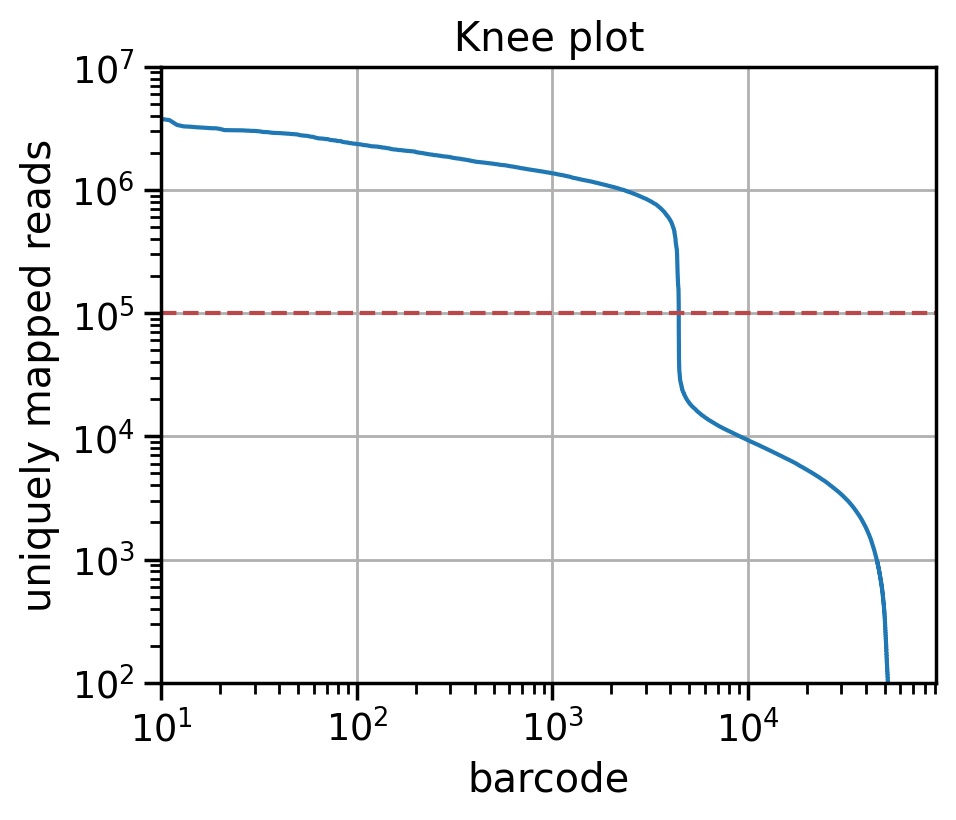

In [44]:
mapping_all = pd.read_csv(mapping_outfile)
plot_bc_rank(mapping_all, cutoff)

## Set cutoff for the number of uniquely mapped reads per nucleus

In [79]:
meta_all['pass_filter'] = meta_all['filtered_uniq_reads'] > cutoff
meta_all['pass_filter'].value_counts()

False    4652
True     4426
Name: pass_filter, dtype: int64

In [80]:
meta_pass = meta_all.loc[meta_all['pass_filter']]
print(f'In total, there are {mapping_all.shape[0]} unique nuclei barcodes detected in the sequencing.')
print(f'{meta_pass.shape[0]} unique nuclei barcodes have unique reads > {cutoff}. These are deemed as valid barcodes.')

In total, there are 53381 unique nuclei barcodes detected in the sequencing.
4426 unique nuclei barcodes have unique reads > 100000. These are deemed as valid barcodes.


## Scatter plots of quality metrics of the passing cells

In [81]:
# set cutoff
NCGN_perc_cutoff=90
NCHN_perc_cutoff=1

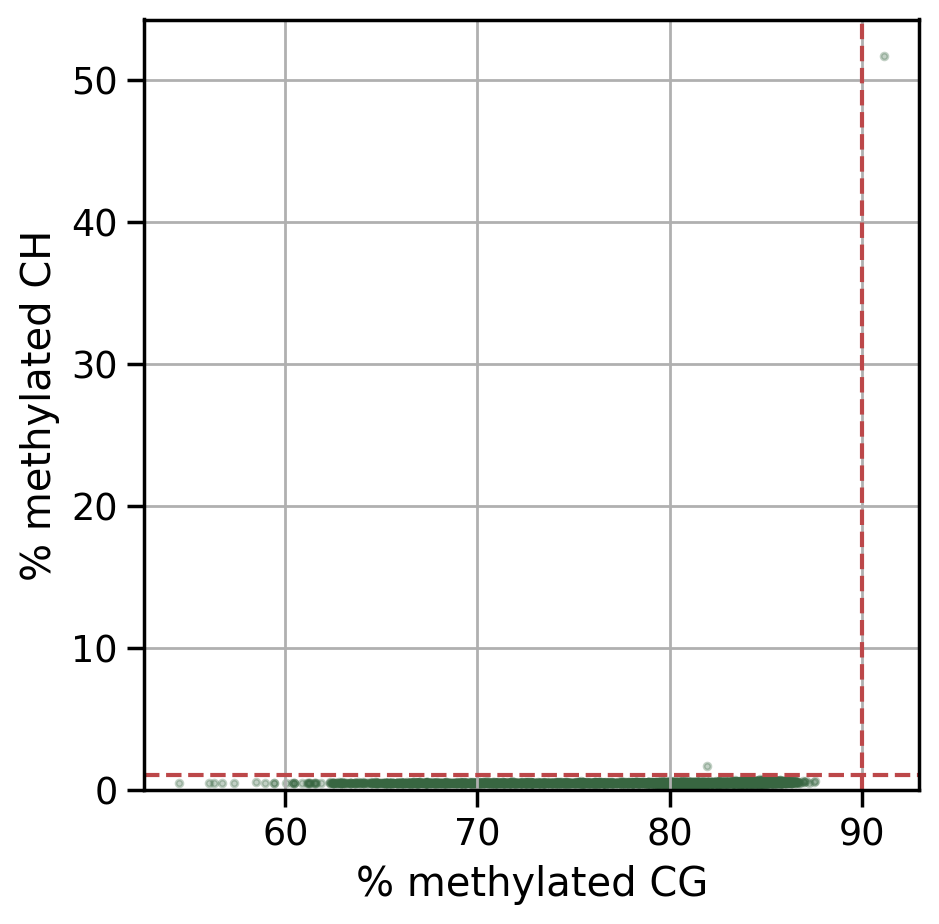

In [82]:
plt.figure(figsize=(5, 5))
plt.scatter(meta_pass['NCGN_perc'], meta_pass['NCHN_perc'],
            color = '#386641', s=6, alpha=0.3)
plt.xlabel('% methylated CG')
plt.ylabel('% methylated CH')
plt.grid(True)
plt.ylim(0,)
# horizontal line at cutoff
plt.axvline(x=NCGN_perc_cutoff, color='#bc4749', linestyle='--')
plt.axhline(y=NCHN_perc_cutoff, color='#bc4749', linestyle='--')
plt.show()

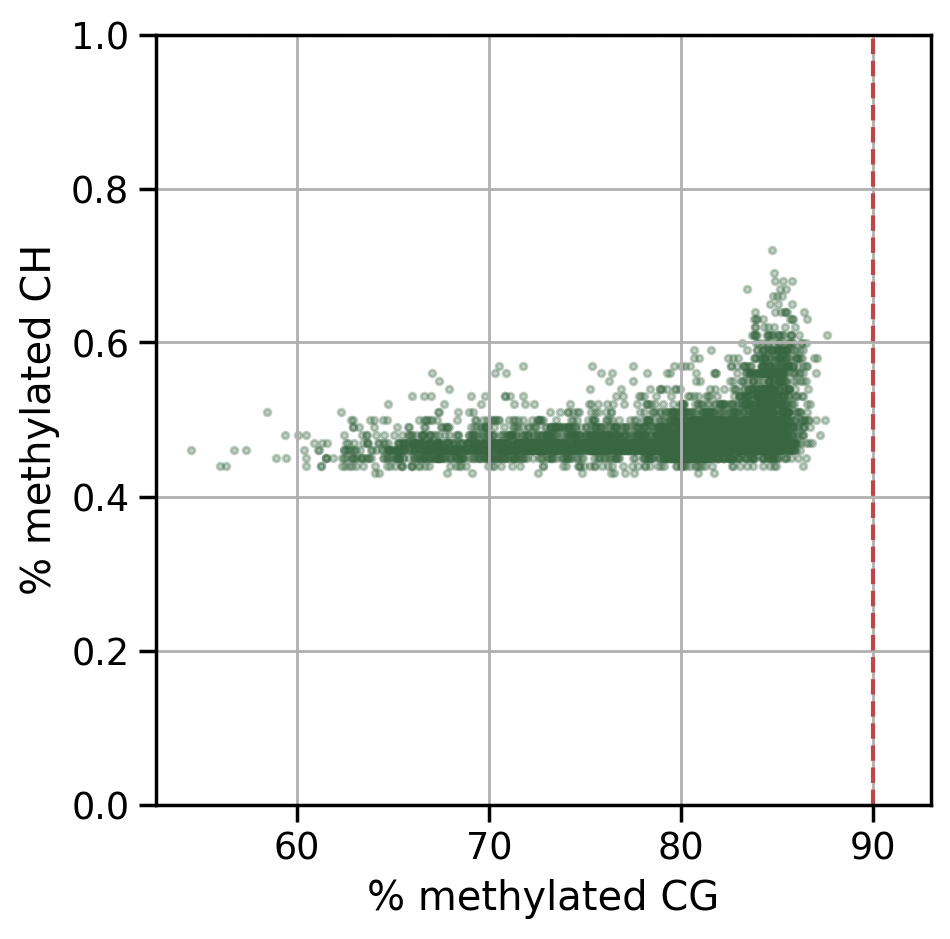

In [83]:
plt.figure(figsize=(5, 5))
plt.scatter(meta_pass['NCGN_perc'], meta_pass['NCHN_perc'],
            color = '#386641', s=6, alpha=0.3)
plt.xlabel('% methylated CG')
plt.ylabel('% methylated CH')
plt.grid(True)
plt.ylim(0,1)
# horizontal line at cutoff
plt.axvline(x=NCGN_perc_cutoff, color='#bc4749', linestyle='--')
plt.axhline(y=NCHN_perc_cutoff, color='#bc4749', linestyle='--')
plt.show()

In [84]:
# count how many nuclei exceed cutoff
meta_pass.loc[meta_pass['NCHN_perc']>NCHN_perc_cutoff][['barcode','NCGN_perc','NCHN_perc']]

,barcode,NCGN_perc,NCHN_perc
3270,PBMC.2B11.CGAATCTCCT_CGGTTATGCC_TCATAAGG,81.95,1.66
5387,PBMC.2C04.TTCAATATAA_CTTCGGCGCA_GGACAATG,91.15,51.70


### Check if the nuclei with distinction in mCG or mCH levels are related to low coverage

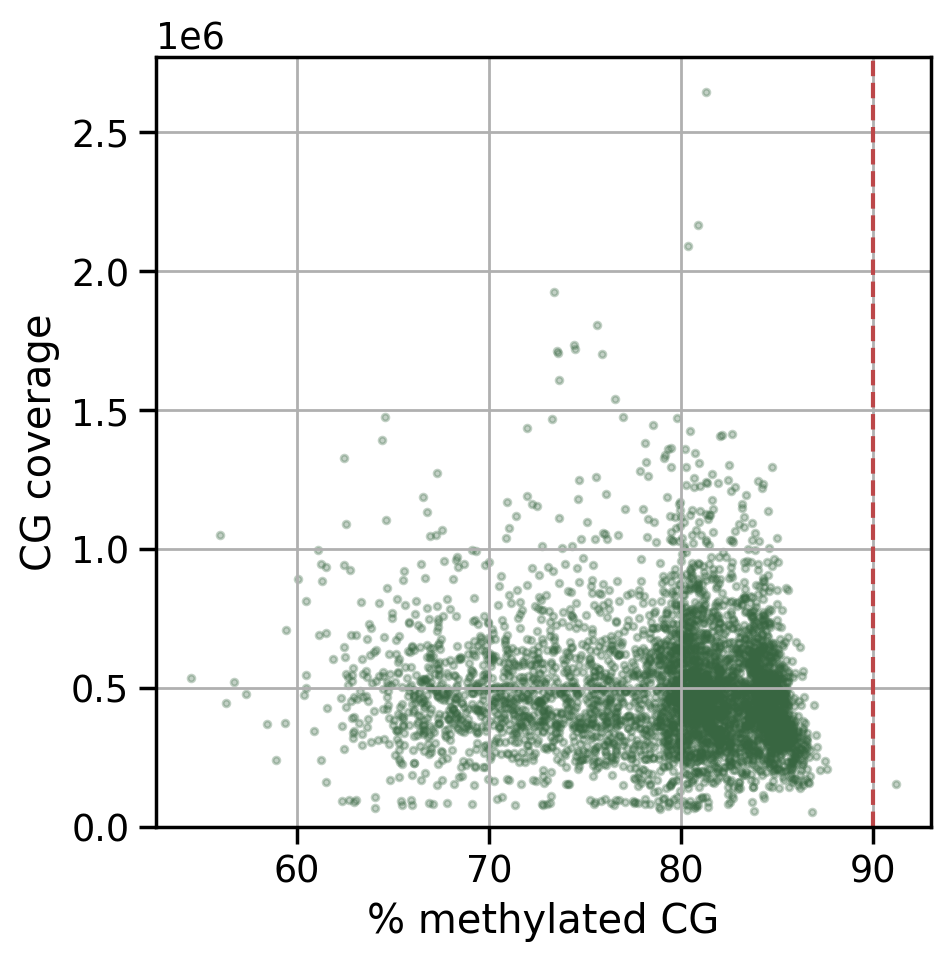

In [85]:
plt.figure(figsize=(5, 5))
plt.scatter(meta_pass['NCGN_perc'], meta_pass['NCGN_cov'], color = '#386641', s=6, alpha=0.3)
plt.xlabel('% methylated CG')
plt.ylabel('CG coverage')
plt.grid(True)
plt.ylim(0,)
# horizontal line at cutoff
plt.axvline(x=NCGN_perc_cutoff, color='#bc4749', linestyle='--')
plt.show()

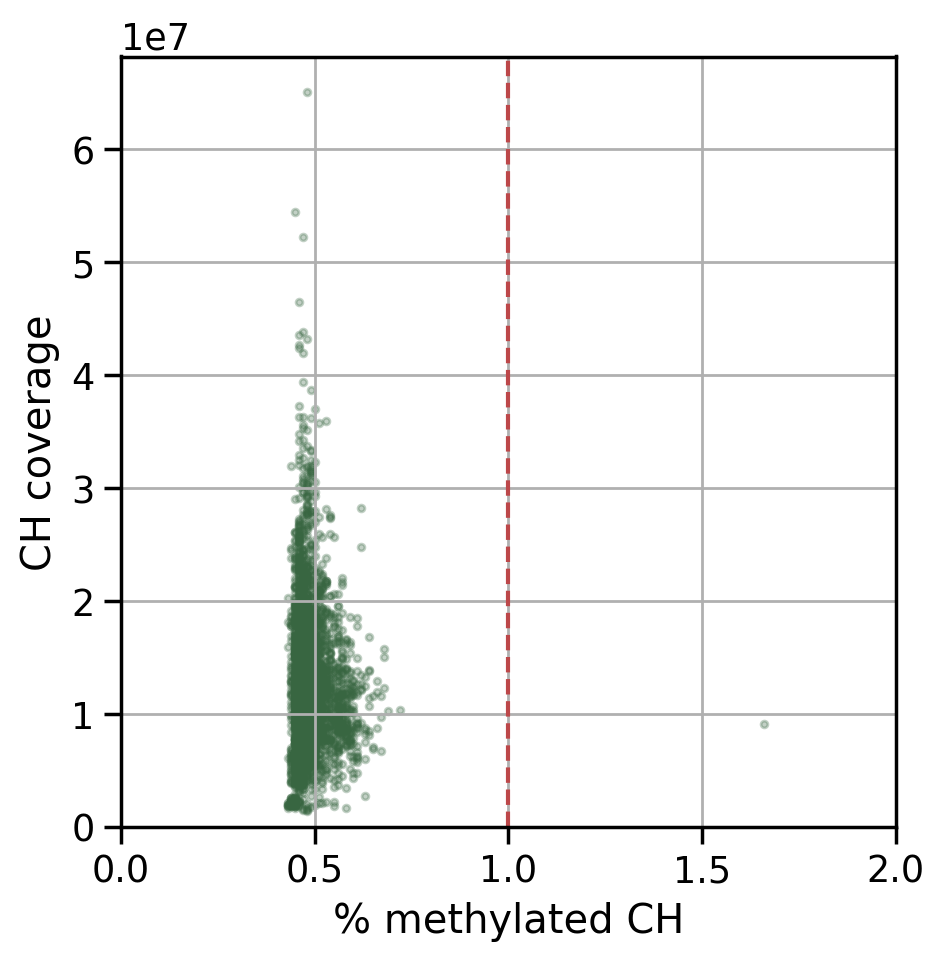

In [86]:
plt.figure(figsize=(5, 5))
plt.scatter(meta_pass['NCHN_perc'], meta_pass['NCHN_cov'], color = '#386641', s=6, alpha=0.3)
plt.xlabel('% methylated CH')
plt.ylabel('CH coverage')
plt.grid(True)
plt.ylim(0,)
plt.xlim(0,2)
# horizontal line at cutoff
plt.axvline(x=NCHN_perc_cutoff, color='#bc4749', linestyle='--')
plt.show()

### Check if outliers come from the same wells in ligation plates

In [87]:
outliers_cg = meta_pass.loc[meta_pass['NCGN_perc']>NCGN_perc_cutoff,['barcode','tgmt_well','i7_well','i5_well']]
outliers_cg

,barcode,tgmt_well,i7_well,i5_well
5387,PBMC.2C04.TTCAATATAA_CTTCGGCGCA_GGACAATG,2C04,A04,E01


In [88]:
outliers_ch = meta_pass.loc[meta_pass['NCHN_perc']>NCHN_perc_cutoff,['barcode','tgmt_well','i7_well','i5_well']]
outliers_ch

,barcode,tgmt_well,i7_well,i5_well
3270,PBMC.2B11.CGAATCTCCT_CGGTTATGCC_TCATAAGG,2B11,A05,C01
5387,PBMC.2C04.TTCAATATAA_CTTCGGCGCA_GGACAATG,2C04,A04,E01


## Set cutoff for methylation levels

In [89]:
meta_pass['pass_filter'] = meta_pass['NCHN_perc'] < NCHN_perc_cutoff
meta_pass['pass_filter'].value_counts()

/scratch/leuven/357/vsc35706/singularity_tmp/ipykernel_3005588/267774963.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  meta_pass['pass_filter'] = meta_pass['NCHN_perc'] < NCHN_perc_cutoff


True     4424
False       2
Name: pass_filter, dtype: int64

In [90]:
print(f"{len(meta_pass[meta_pass['pass_filter'] == False])} nuclei were filtered out")

2 nuclei were filtered out


In [91]:
meta_pass = meta_pass.loc[meta_pass['pass_filter']]
print(f'{meta_pass.shape[0]} nuclei passed QC.')

4424 nuclei passed QC.


## 💾 Save the barcodes of nuclei that passed filtering & Read saved metadata

In [92]:
meta_pass.drop(columns=['pass_filter'], inplace=True)
meta_pass.to_csv(meta_pass_merged_file, index=False)
print(f'File saved to {meta_pass_merged_file}')

File saved to /staging/leuven/stg_00064/Xinran/project/sciMET_PBMC/20251001_sciMET_PBMC_processing/QC/metadata.passingCells.csv


In [93]:
meta_pass = pd.read_csv(meta_pass_merged_file)
meta_pass.head(3)

,barcode,trimmed_reads,mapped_uniq_reads,dedup_uniq_reads,filtered_uniq_reads,batch,uniq_map_rate,dup_rate,filtered_perc,chrM_NCGN_count,...,GC_NC_60_79,GC_NC_80_100,i7,i5,tgmt,i7_well,i5_well,tgmt_well,tgmt_plate,sample
0,PBMC.3G02.ATGAGTTCTC_AGGAGAGAAC_CATTAATC,28232982,25016470,6008680,4841288,PBMC,88.607254,75.981104,19.428427,31,...,0.575229,0.218875,ATGAGTTCTC,AGGAGAGAAC,CATTAATC,A12,B02,3G02,MET TAG PLATE 3,sciMET_PBMC.sample2
1,PBMC.2B04.TATTCCGTTA_GGCAATGAGA_AGTATGCC,12804540,11183478,4852430,4042722,PBMC,87.339943,56.610725,16.686650,18,...,0.562682,0.181314,TATTCCGTTA,GGCAATGAGA,AGTATGCC,A09,B01,2B04,MET TAG PLATE 2,sciMET_PBMC.sample1
2,PBMC.3D05.CGAATCTCCT_GGCAATGAGA_AGTTCCAT,13572610,11959828,4712936,3922988,PBMC,88.117378,60.593614,16.761272,17,...,0.549317,0.193298,CGAATCTCCT,GGCAATGAGA,AGTTCCAT,A05,B01,3D05,MET TAG PLATE 3,sciMET_PBMC.sample1


## Quality metrics

### all batches combined

In [96]:
plotlist = [
    {'feature': 'tss_enrich',       'label': 'TSS enrichment'},    
    {'feature': 'FRIP',             'label': 'FRiP'},    
    {'feature': 'GC_DROPOUT',       'label': 'GC dropout'},    
    {'feature': 'mean_frag_size',   'label': 'Mean fragment size'},    
    {'feature': 'trimmed_reads',    'label': '# total reads',                 'log_scale':True},
    {'feature': 'filtered_uniq_reads','label': '# filtered uniquely mapped reads', 'log_scale':True},
    {'feature': 'uniq_map_rate',    'label': 'Mapping rate (%)'},    
    {'feature': 'dup_rate',         'label': 'Duplication rate (%)'},    
    {'feature': 'coverage',         'label': '% genome-wide coverage'},    
    {'feature': 'depth',            'label': 'X coverage'},    
    {'feature': 'NCGN_perc',        'label': '% mCG'},    
    {'feature': 'NCHN_perc',        'label': '% mCH'},    
    {'feature': 'NCGN_count',       'label': 'CG coverage',     'log_scale':True},    
    {'feature': 'NCHN_count',       'label': 'CH coverage',     'log_scale':True},    
]

count    4424.000000
mean        0.901415
std         0.030056
min         0.771500
25%         0.882875
50%         0.900400
75%         0.918600
max         1.069400
Name: tss_enrich, dtype: float64
count    4424.000000
mean        0.559526
std         0.046188
min         0.360700
25%         0.535700
50%         0.558950
75%         0.580625
max         0.881100
Name: FRIP, dtype: float64
count    4424.000000
mean        5.148487
std         1.192708
min         0.365499
25%         4.559634
50%         5.180725
75%         5.796002
max        10.993426
Name: GC_DROPOUT, dtype: float64
count    4424.000000
mean      153.834984
std         8.158452
min       108.650000
25%       148.400000
50%       153.325000
75%       158.970000
max       185.890000
Name: mean_frag_size, dtype: float64
count    4.424000e+03
mean     4.932027e+06
std      2.816361e+06
min      6.830120e+05
25%      3.011445e+06
50%      4.352200e+06
75%      6.187798e+06
max      3.759354e+07
Name: trimmed_reads, d

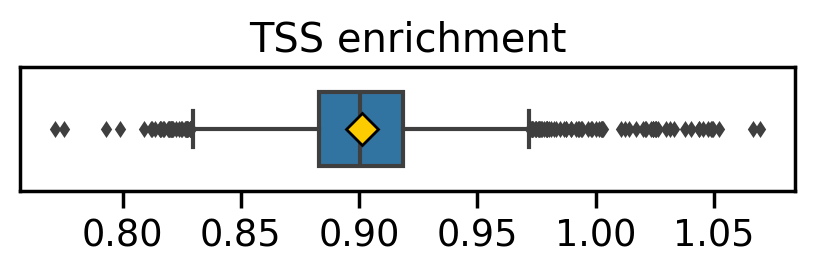

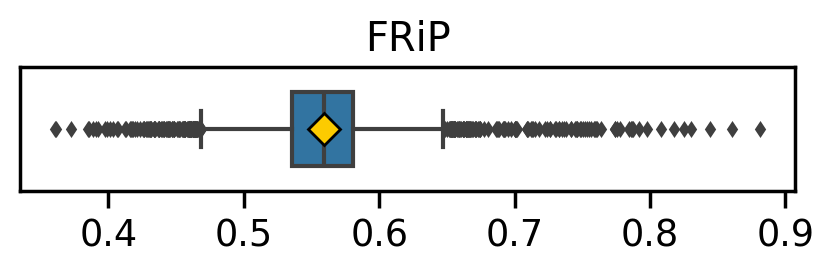

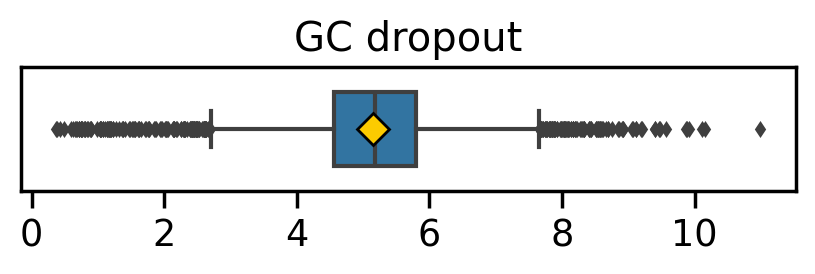

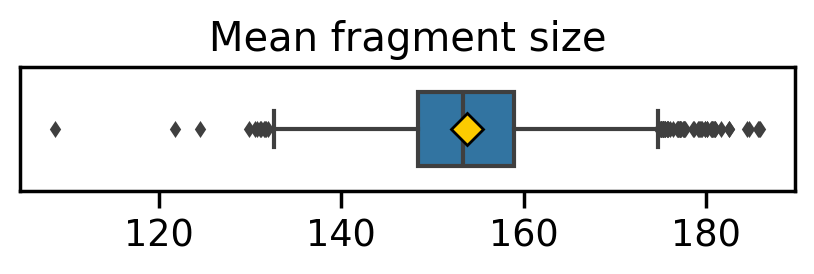

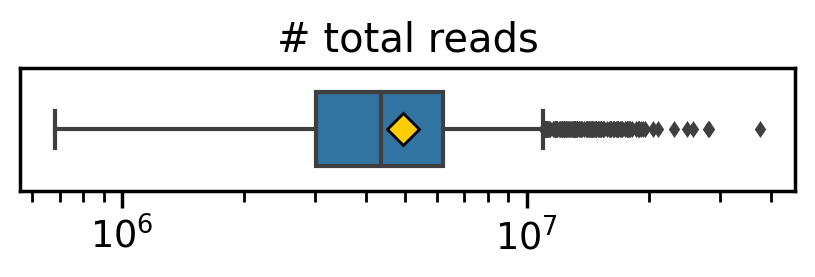

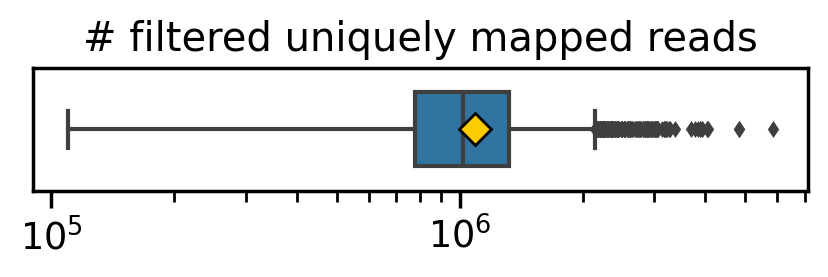

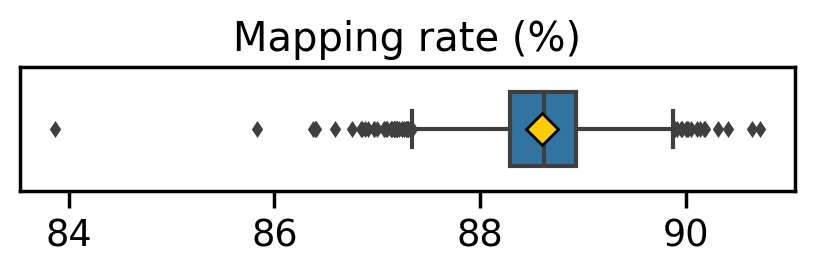

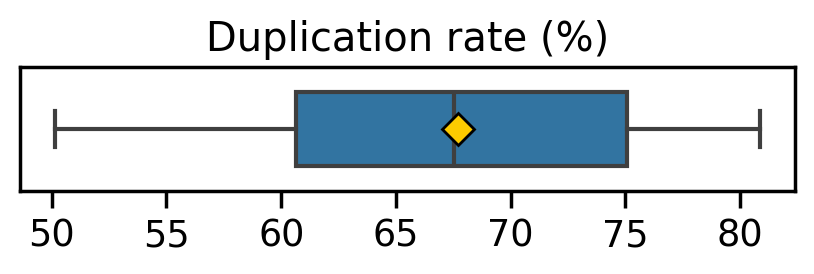

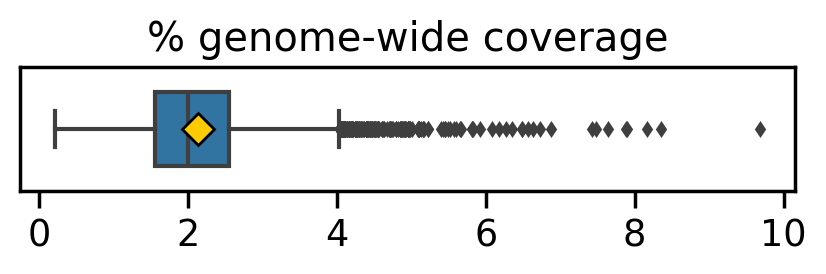

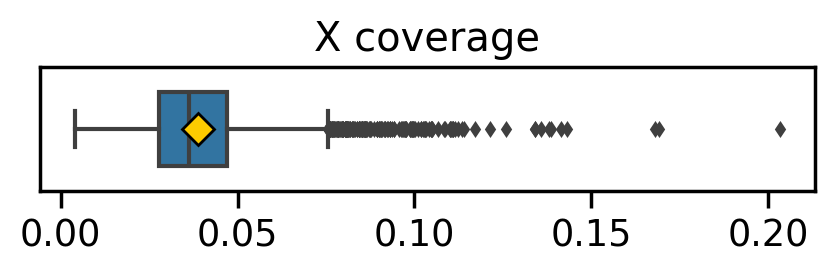

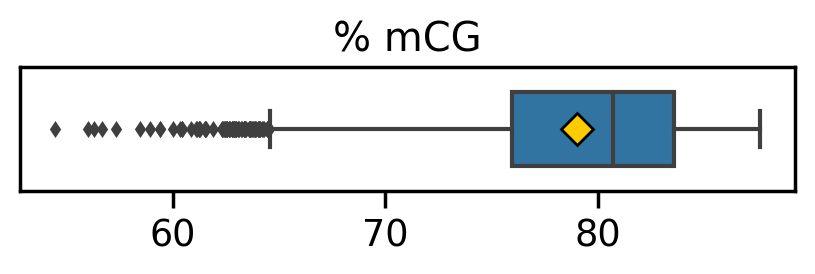

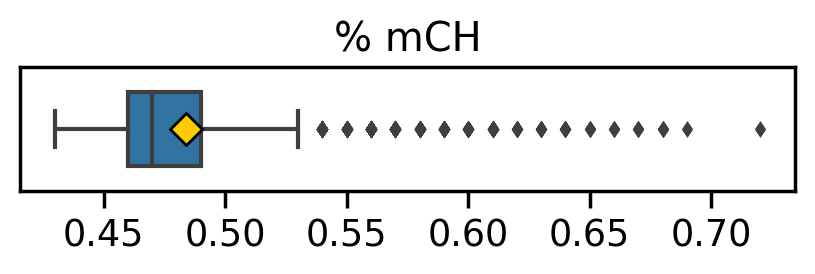

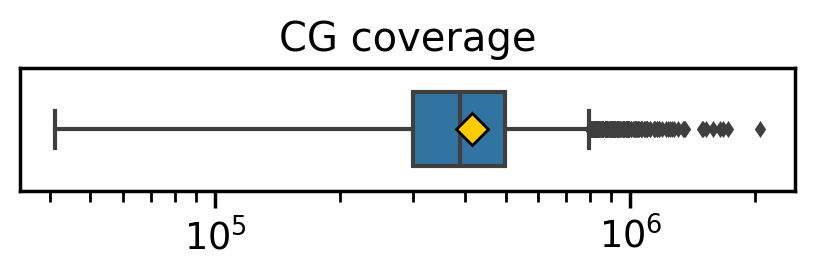

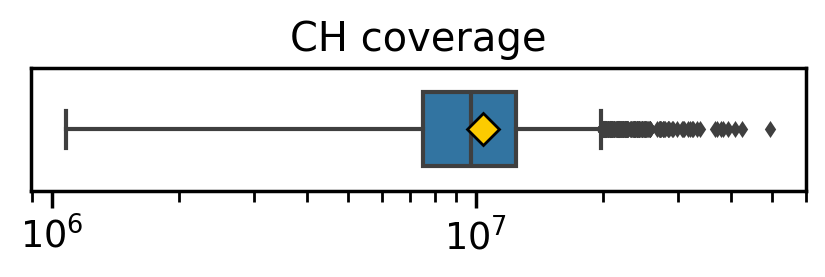

In [97]:
for plotopts in plotlist:
    opts = {
        'data': meta_pass,
        'feature': plotopts['feature'],
        'label': plotopts['label'],
        'orientation': 'h',
        'log_scale': plotopts.get('log_scale', False)
    }
    plot_boxplot(**opts)

print(f"Mean coverage for CG: {round(meta_all.NCGN_count.mean())}")
print(f"Mean coverage for CH: {round(meta_all.NCHN_count.mean())}")

### plot separately for case/ctrl to check if there is sample-related batch effect

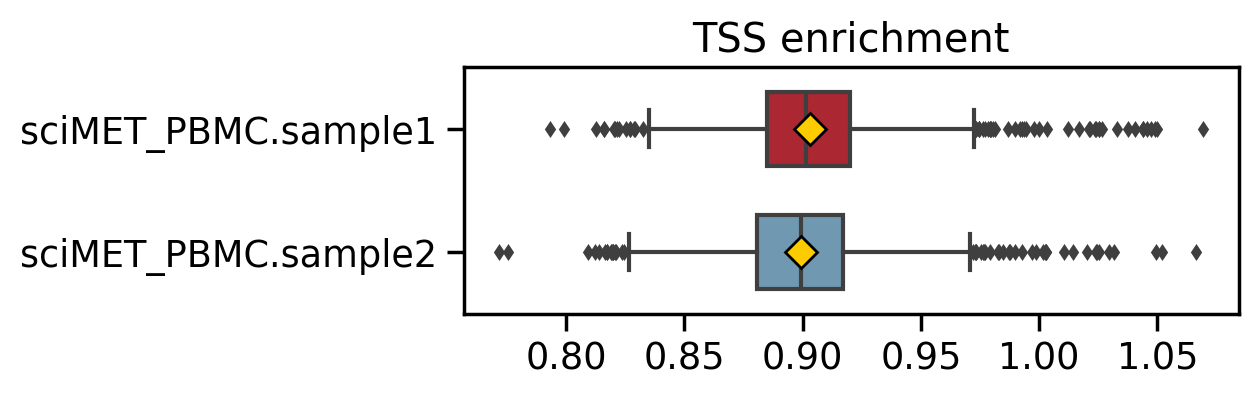

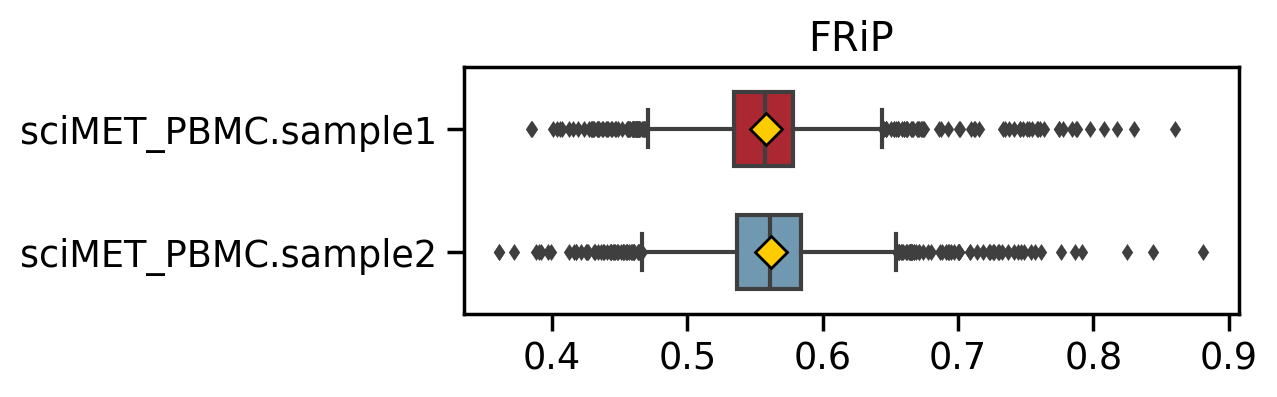

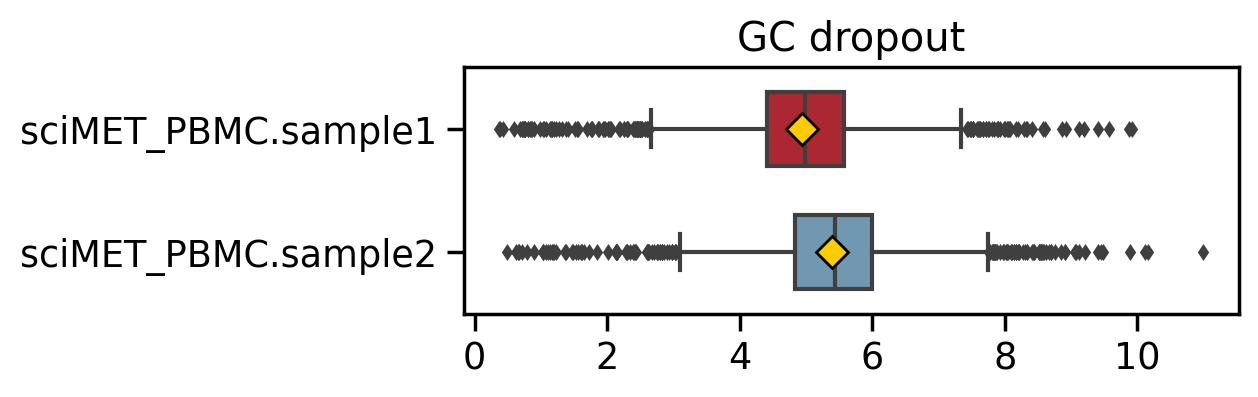

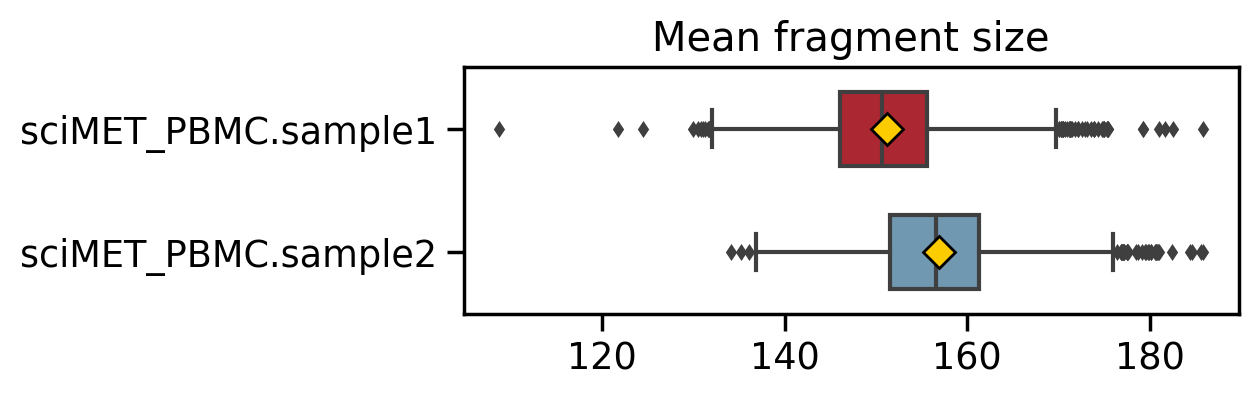

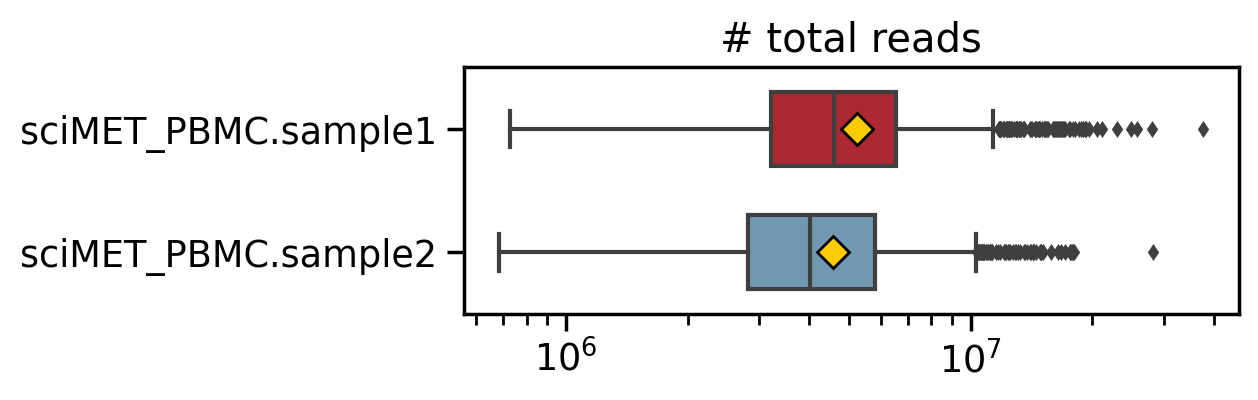

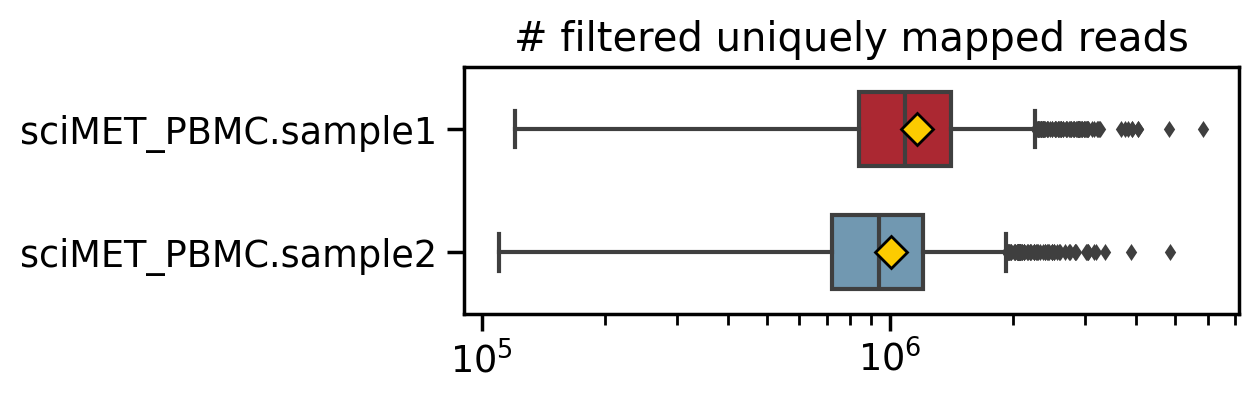

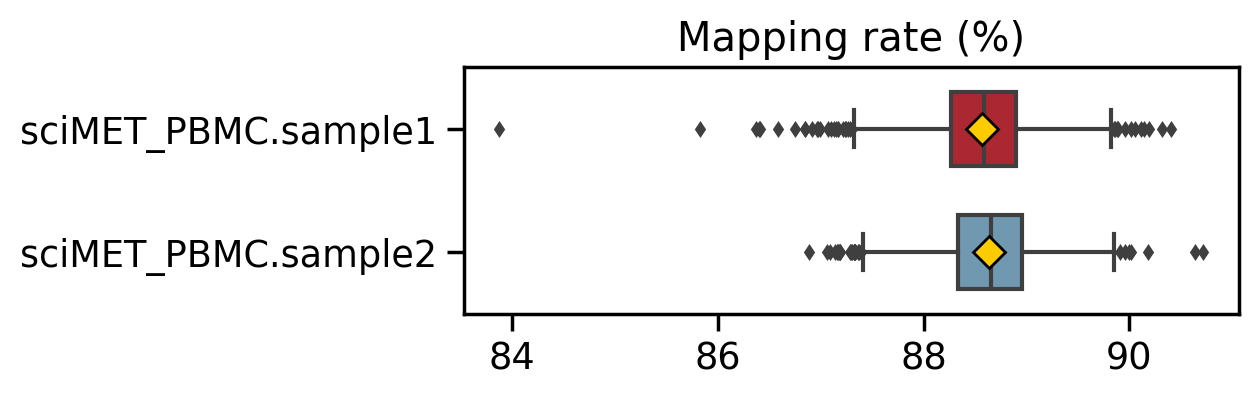

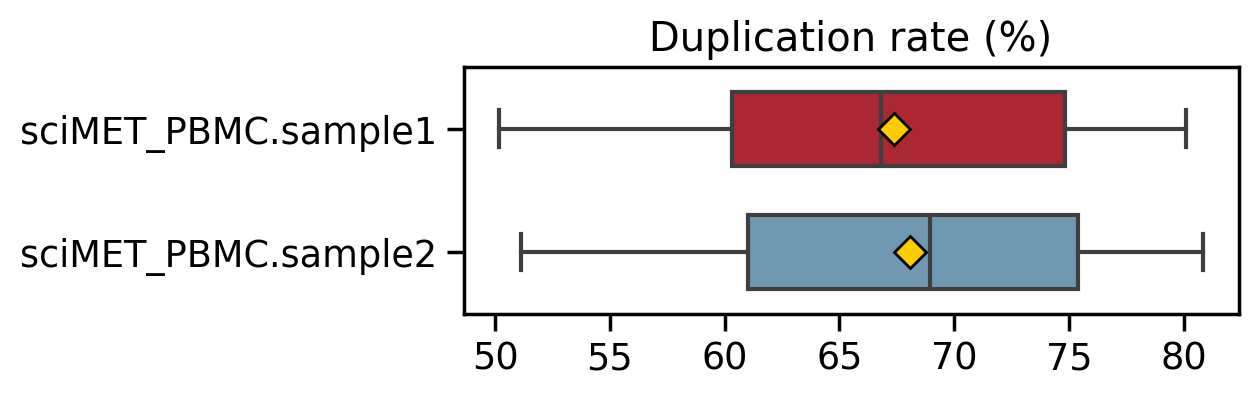

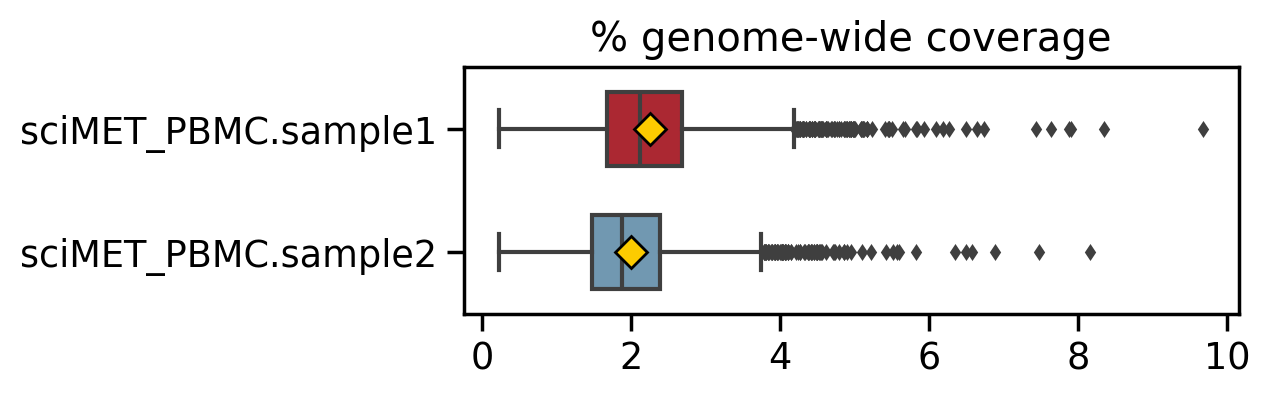

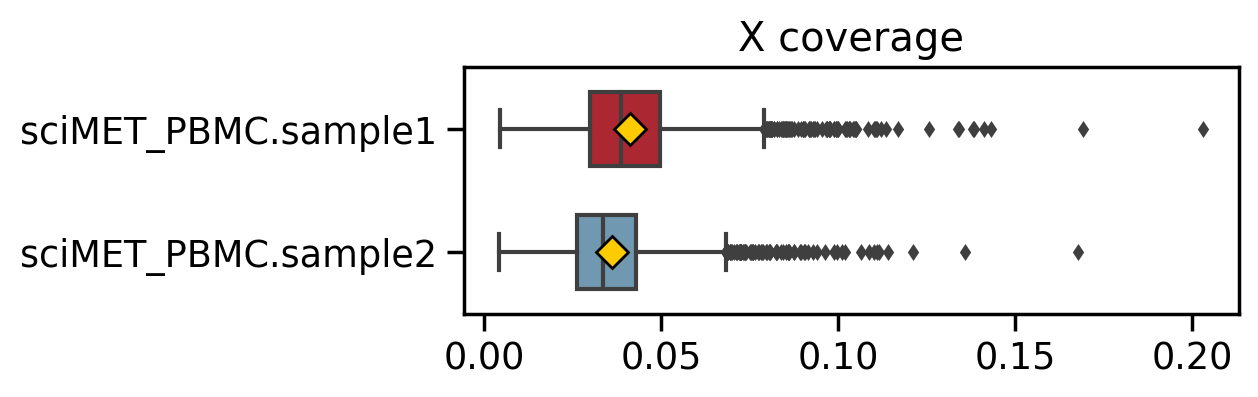

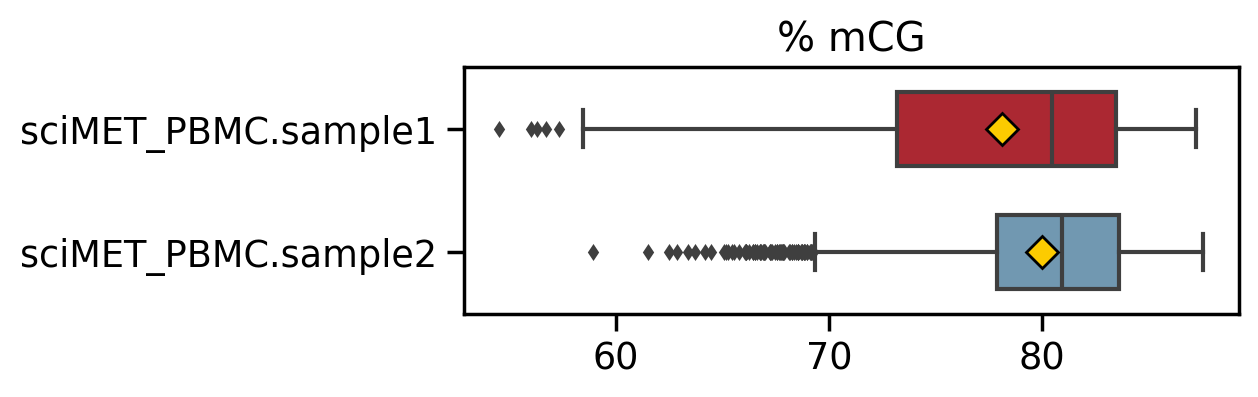

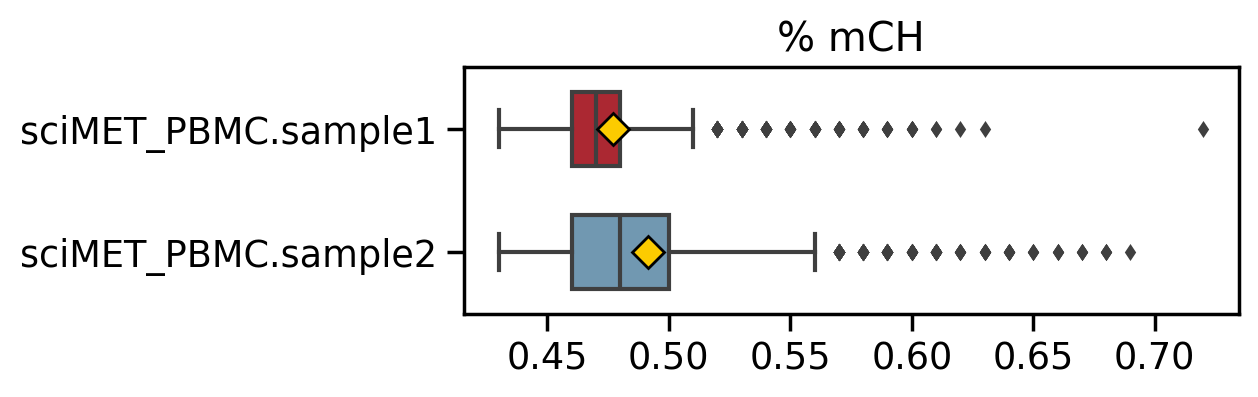

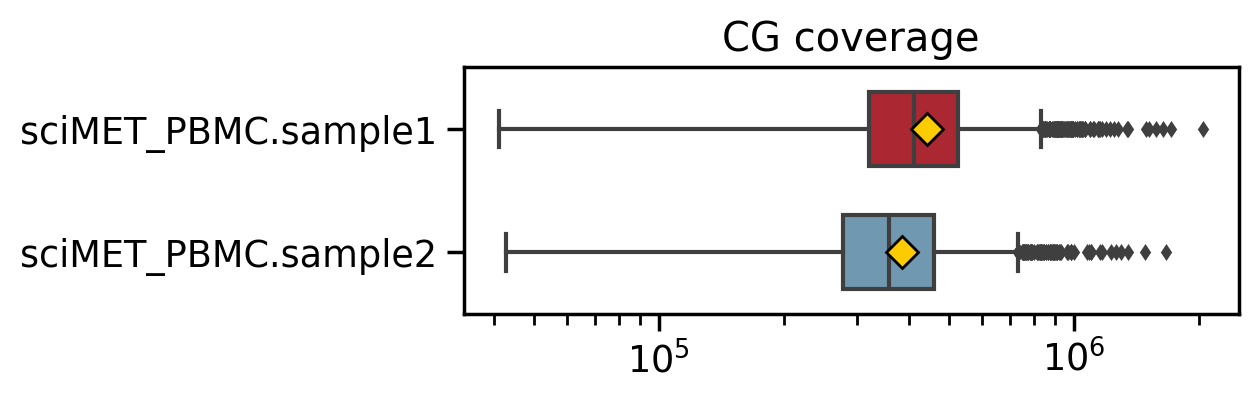

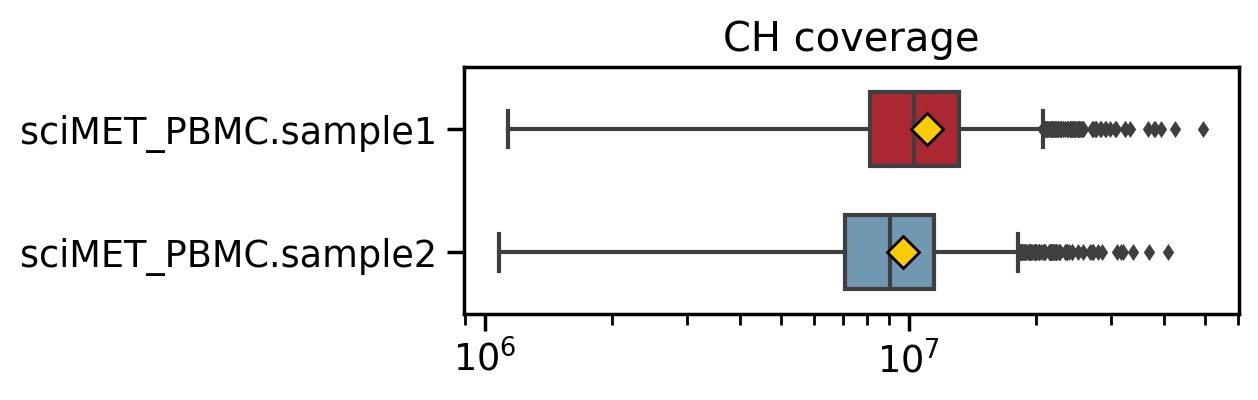

In [99]:
group_by='sample'

figsize=(5, 1.6)
category_colors = {
    'sciMET_PBMC.sample1': '#c1121f',  
    'sciMET_PBMC.sample2': '#669bbc', 
}

for plotopts in plotlist:
    opts = {
        'data': meta_pass,
        'group_by': group_by, 
        'figsize': figsize,
        'feature': plotopts['feature'],
        'label': plotopts['label'],
        'orientation': 'h',
        'log_scale': plotopts.get('log_scale', False),
        'palette': category_colors,
        'order': category_colors.keys()
    }
    plot_boxplot_sep(**opts)

### plot seperately for each plate

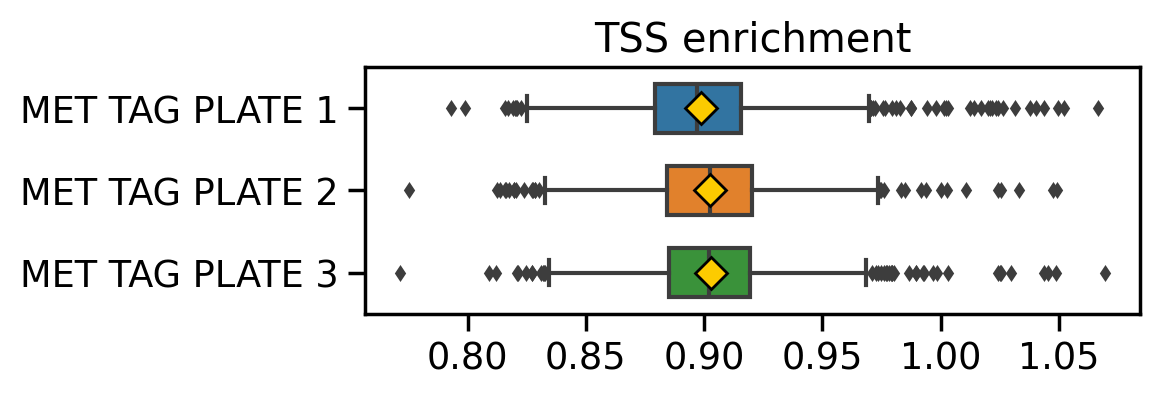

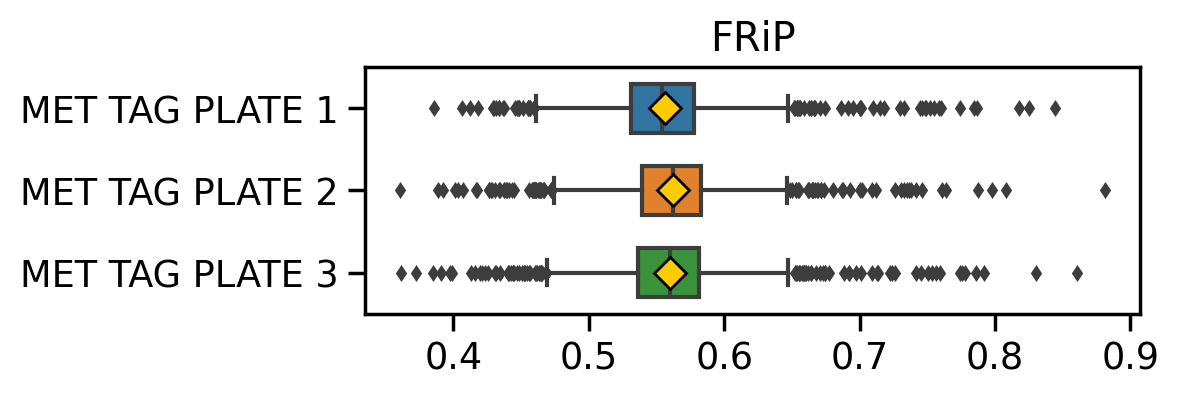

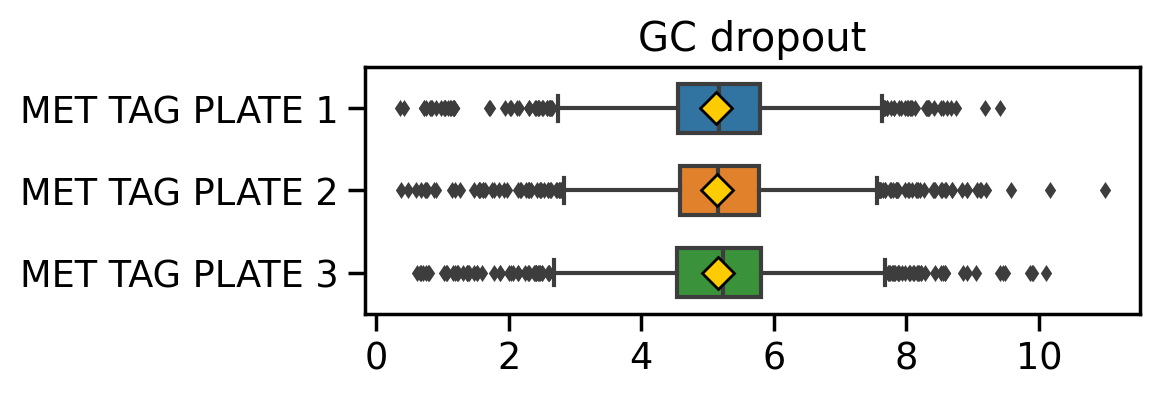

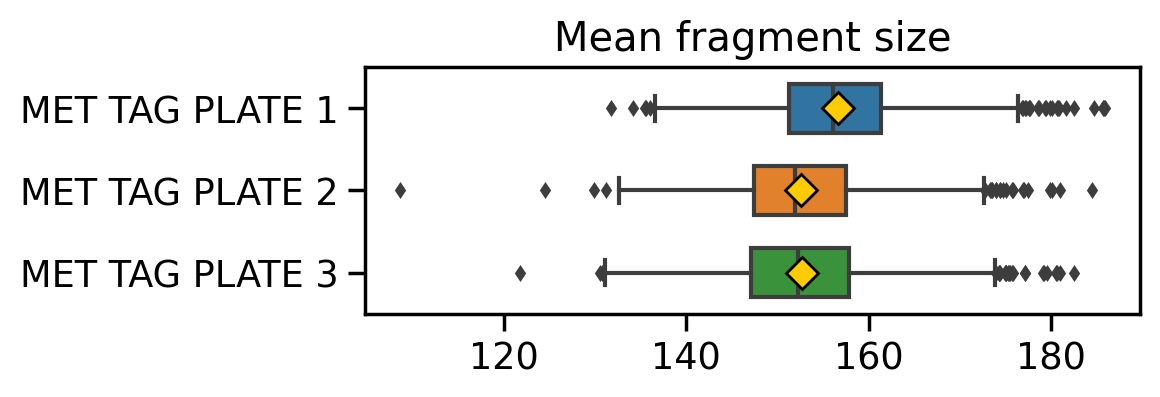

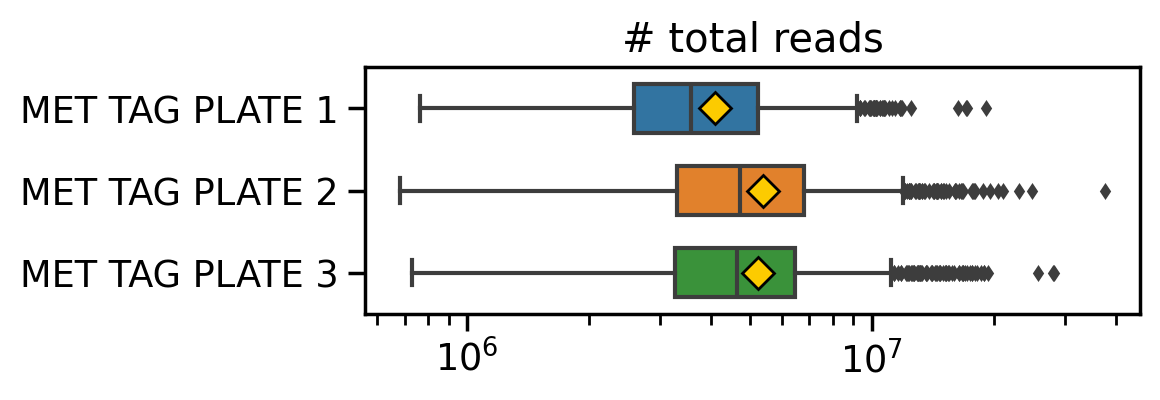

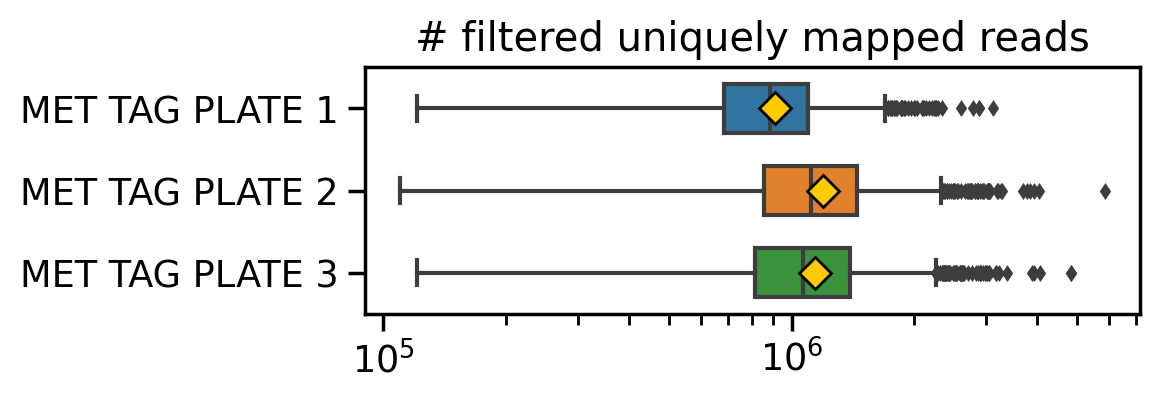

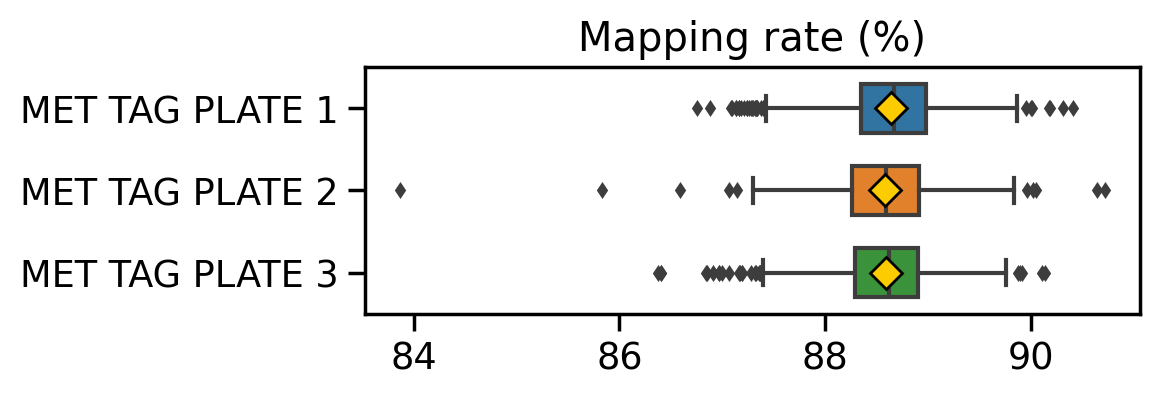

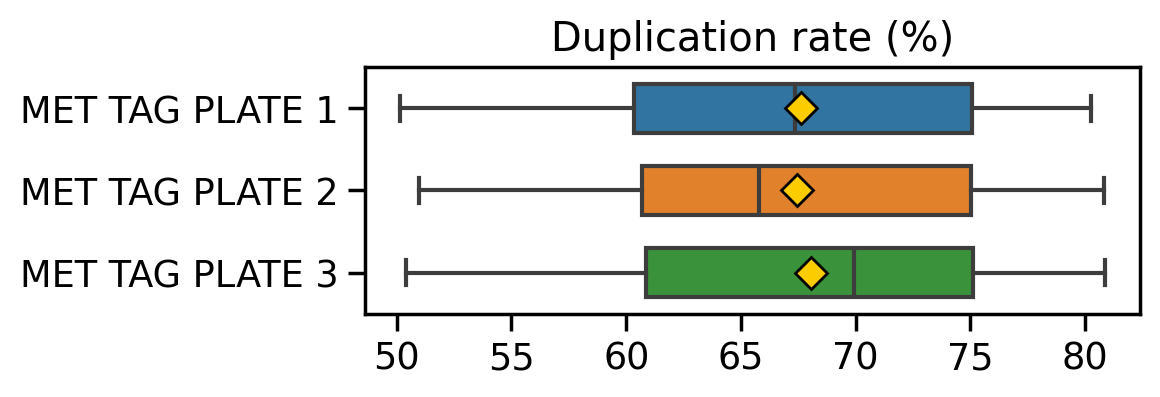

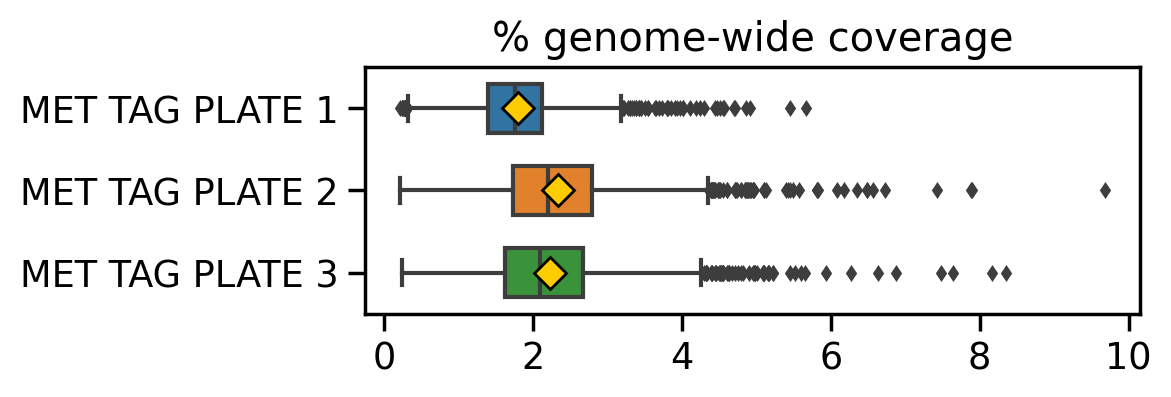

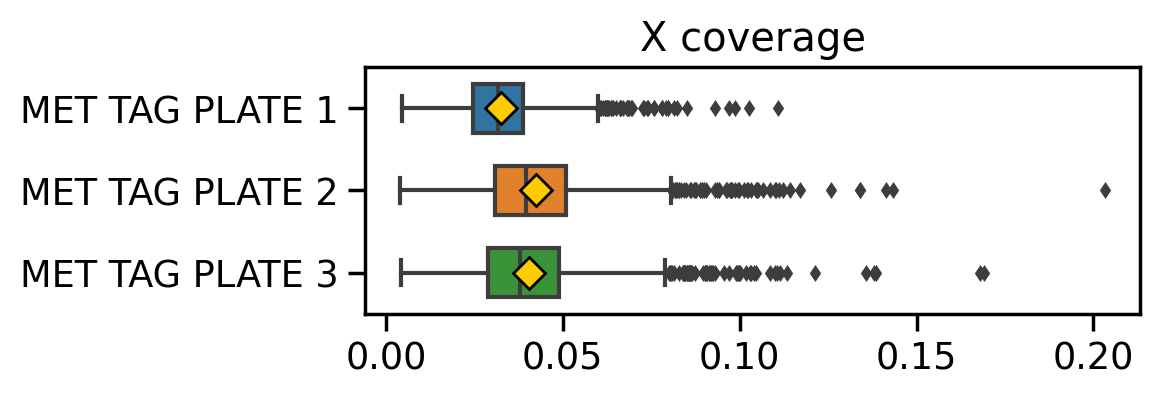

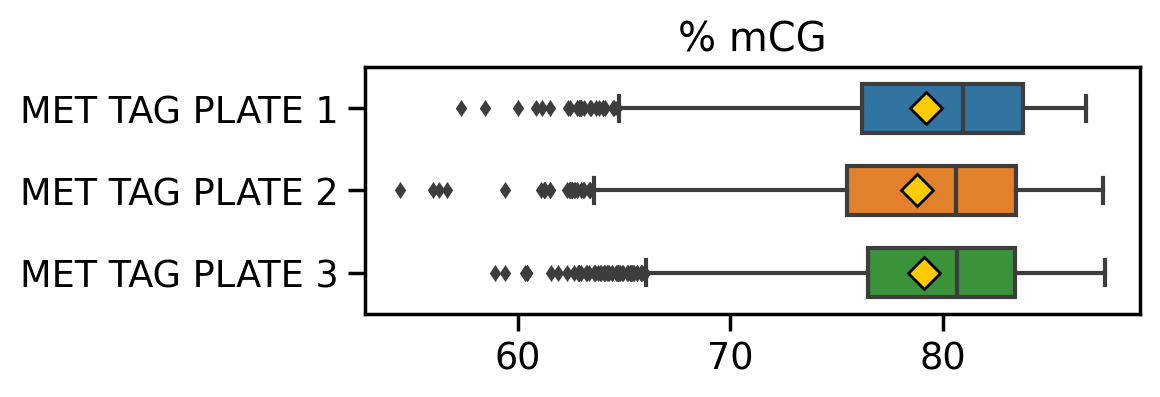

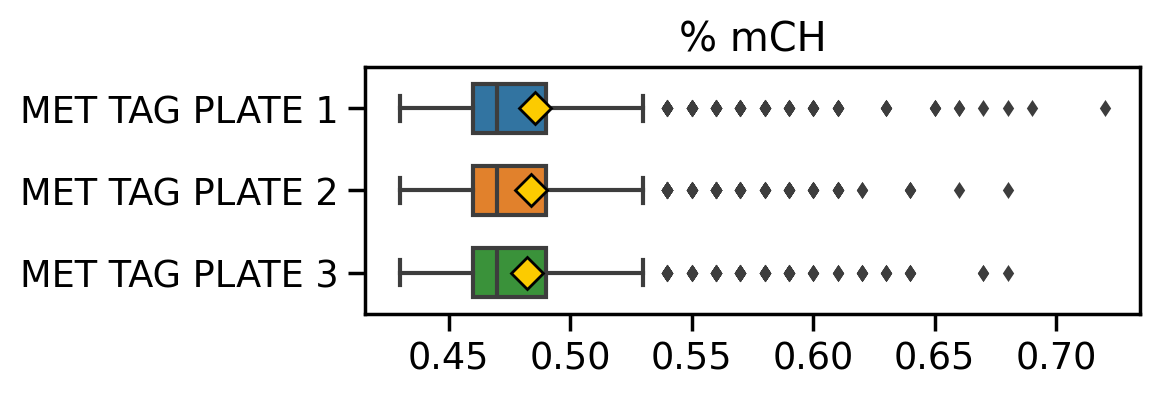

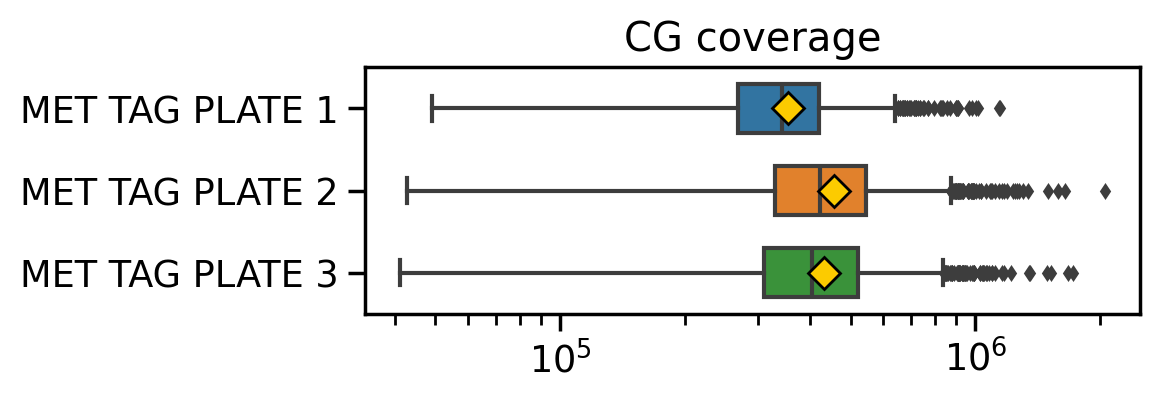

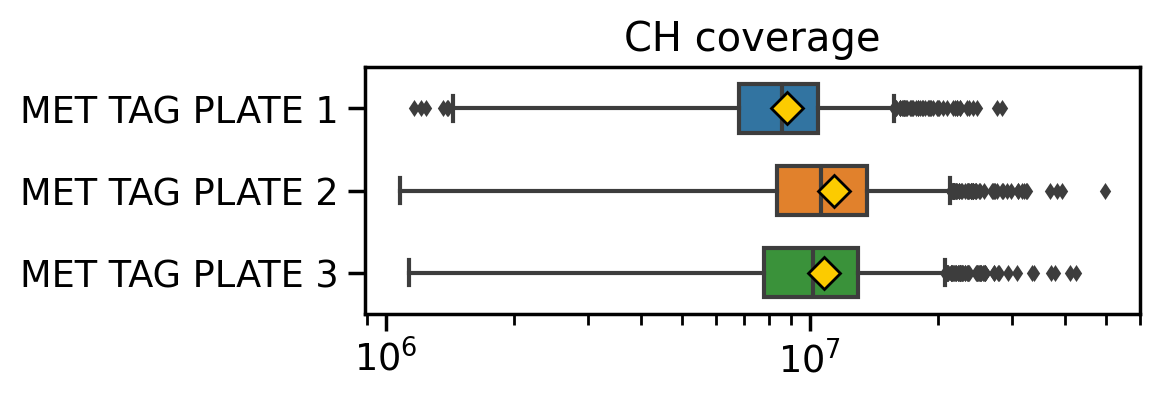

In [100]:
figsize=(5, 1.6)
group_by='tgmt_plate'
tgmt_plates = ['MET TAG PLATE 1', 'MET TAG PLATE 2', 'MET TAG PLATE 3']
tgmt_plate_palette = dict(zip(tgmt_plates, sns.color_palette("tab10", len(tgmt_plates))))

for plotopts in plotlist:
    opts = {
        'data': meta_pass,
        'group_by': group_by, 
        'figsize': figsize,
        'feature': plotopts['feature'],
        'label': plotopts['label'],
        'orientation': 'h',
        'log_scale': plotopts.get('log_scale', False),
        'palette': tgmt_plate_palette,
        'order': tgmt_plate_palette
    }
    plot_boxplot_sep(**opts)

## 🎨 Pairs plot for QC metrics

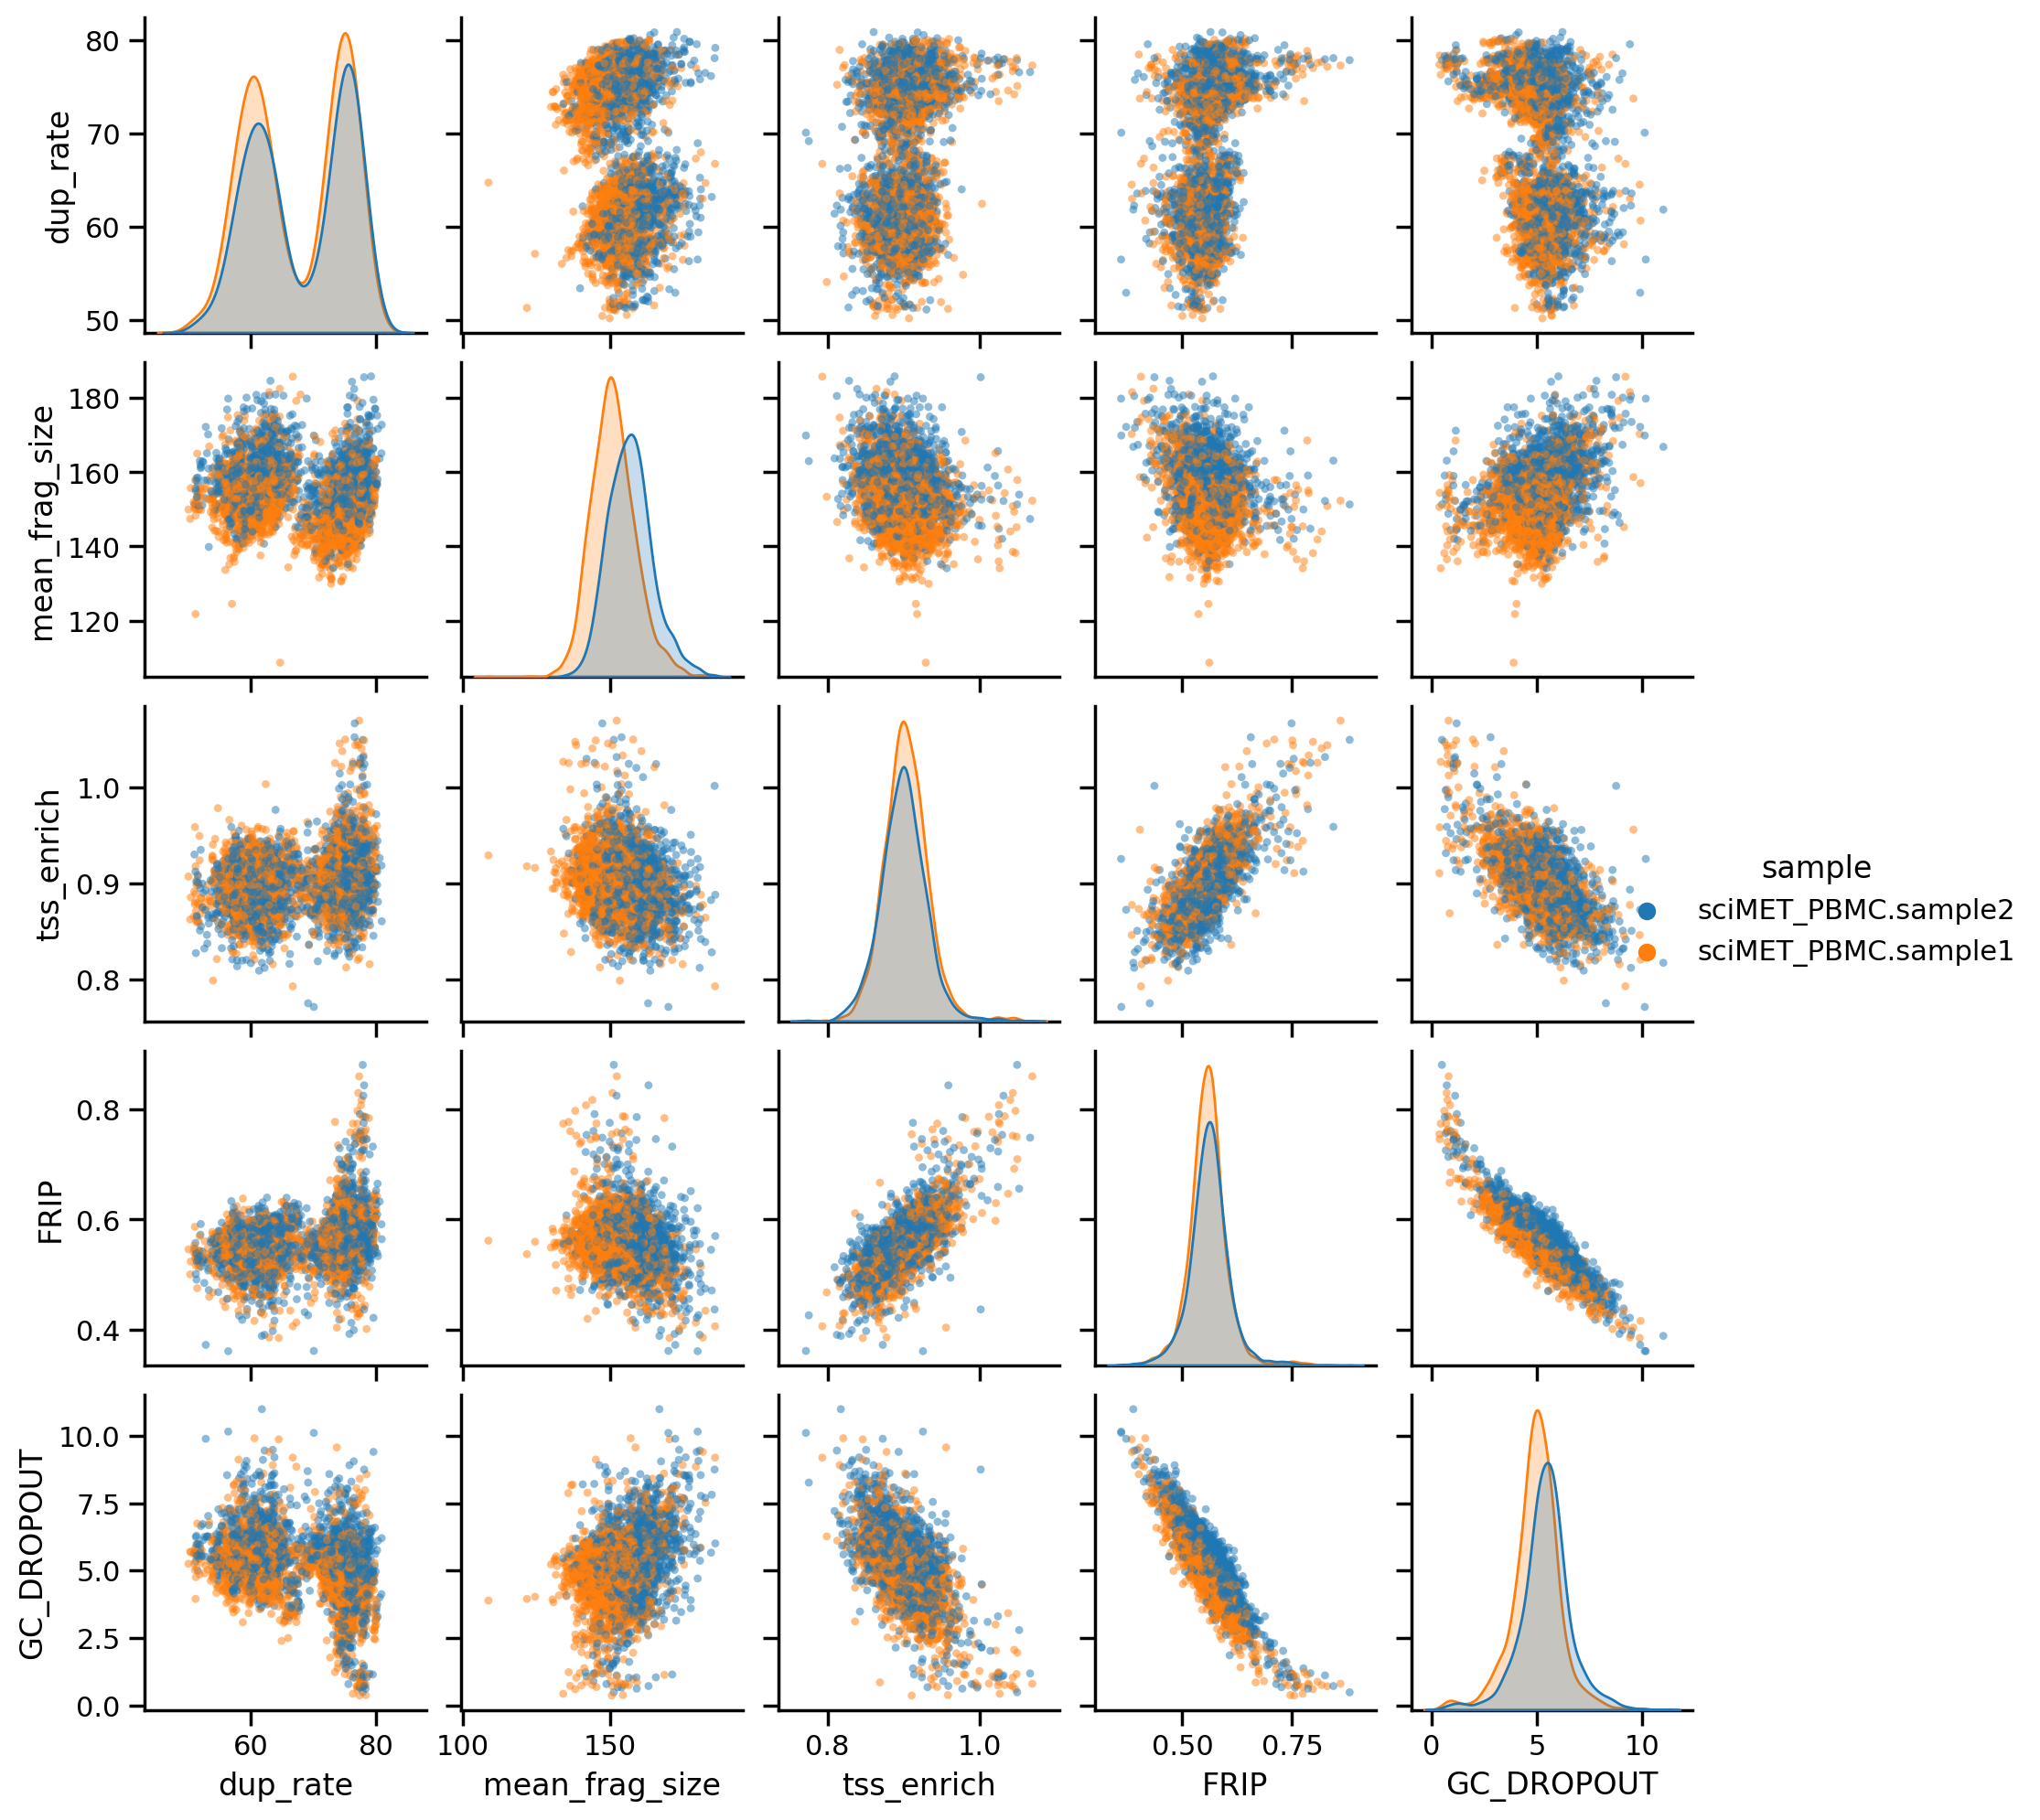

In [102]:
sns.set_context(context='notebook', font_scale=1)
metrics = ['dup_rate', 'mean_frag_size', 'tss_enrich', 'FRIP','GC_DROPOUT'] 
g = sns.pairplot(data=meta_pass, vars=metrics, hue='sample', plot_kws={'s': 10, 'alpha':0.5, 'edgecolor': 'none'})
g.fig.set_size_inches(11, 10)
pairs_plot_file = os.path.join(qc_dir, 'qc_metrics.pairs_plot.pdf')
plt.savefig(pairs_plot_file)
plt.show()

## 🎨 Fragment size distribution

In [103]:
# get all files of fragment size metrics
file_pattern = os.path.join(experiment_dir, pattern, 'frag', '*.fragment_size_summary.tsv')
file_list = glob.glob(file_pattern)

# subset to specific barcodes
meta_pass = pd.read_csv(meta_pass_merged_file)
barcodes = meta_pass['barcode'].tolist()
file_list = [f for f in file_list if any(b in f for b in barcodes)]
print(f'In total, there are {len(file_list)} barcodes')

In total, there are 4424 barcodes


Maximum value of fragment size: 87


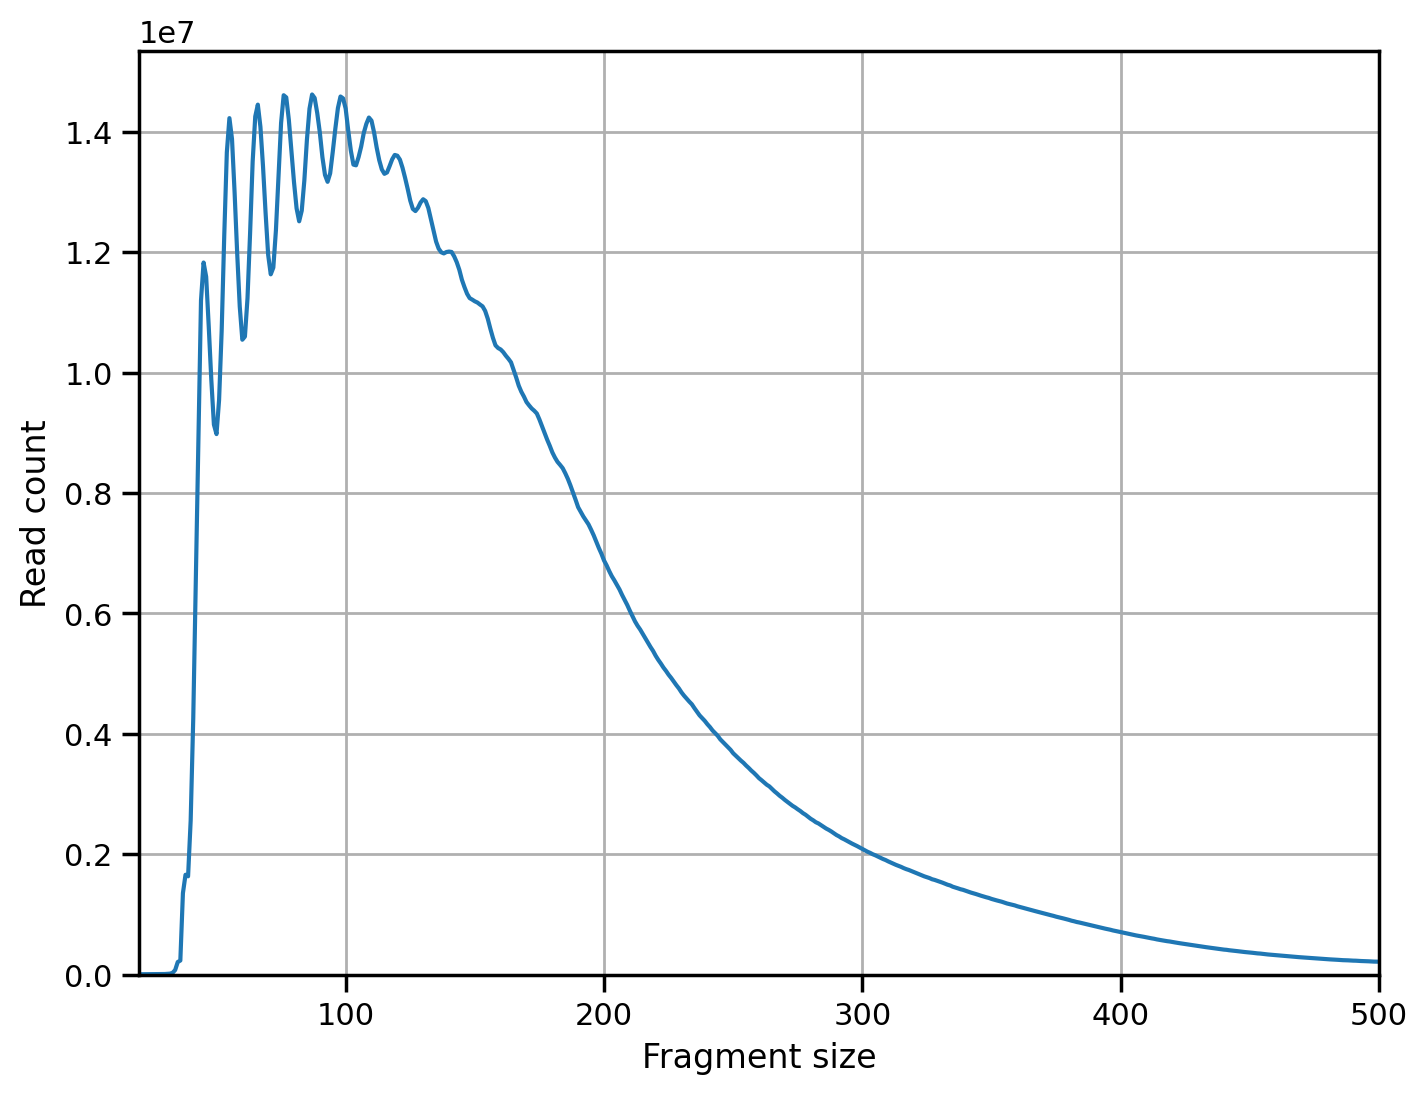

In [104]:
plot_frag_size(file_list)